<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/08_Phishing_Detection/QRAC_EthereumPhishing_Ray2023.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QRAC-encoded QSVM and VQC for Ethereum phishing detection: Ray et al. (2023) step by step

This notebook re-implements, runs and checks the experiments of

> Anupama Ray, Sai Sakunthala and Anil Prabhakar,
> "Improving phishing detection in Ethereum transaction network using Quantum Machine Learning",
> 2023 IEEE International Conference on Quantum Computing and Engineering (QCE), pp. 1107-1113.
> doi:10.1109/QCE57702.2023.00125

**What the notebook does.** Every Ethereum account (node) is described by 7 statistics of the transaction graph (in-degree,
out-degree, degree, in-strength, out-strength, strength, number of neighbours). The notebook downloads the authors' own
train and test feature files from their public GitHub repository (pinned commit) and then trains and compares

* a **quantum-kernel SVM (QSVM-qiskit)** and a **Variational Quantum Classifier (VQC)**, each with the textbook **ZZ feature map**
  (7 qubits, real-valued features) and with the paper's **Quantum Random Access Codes (QRAC)**: binarised features in a 3-qubit
  (3,1)-QRAC or a 2-qubit concatenated (3,1)-QRAC, and categorised features in (2,1)- and (3,1)-QRACs;
* the **annealing QSVM** (SVM dual as a QUBO, solved here by simulated annealing in place of the D-Wave machine);
* the **encoding ablation over 19 benchmark ansatzes** (Figures 6 and 7 of the paper: QRAC against Z, ZZ and amplitude encoding);
* a **noisy-simulator stand-in** for the IBM hardware rows of Tables II and III (Qiskit fake backends of the same devices);
* a classical **SVM, LightGBM and random forest** on exactly the same inputs.

The last section prints the paper's numbers next to ours and gives a verdict per claim.

**How to run it.** Open it in Google Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. `FAST_MODE = True`
(sub-10-minute class demo: 2,200 test nodes, 30 COBYLA iterations, 5 of the 19 ansatzes) and `FAST_MODE = False` (the paper's budgets:
all 11,000 test nodes, 100 COBYLA iterations, 3 seeds, all 19 ansatzes) are switched in the configuration cell; the saved run is the full one (`FAST_MODE = False`) and took about 18 minutes on a laptop CPU (the FAST path about 3 minutes). No account, token or GPU is needed: the data come from a public GitHub
repository, not from a gated Hugging Face dataset, so no Hugging Face token is involved (a gated dataset would need the reader's
own token in Colab Secrets, `HF_TOKEN`).

**What you get at the end.** Tables of macro-F1 / phishing-F1 / phishing-recall / false negatives for 60+ models, the figures of
the encodings and circuits, and a "paper vs this notebook" verdict table.

## The paper in one page

**Problem.** Find phishing accounts in the Ethereum transaction graph. Phishing nodes are extremely rare (about 1 in 2,500
unlabelled nodes; labels come from public Etherscan reports), so the task is an extreme class-imbalance / anomaly problem in which
missed phishing accounts (false negatives) are the costly error.

**Decision.** Binary classification of one node from 7 graph statistics (Chen et al. 2020): phishing vs not phishing.

**Method.** *QSVM-qiskit*: quantum kernel `K(x,y) = |<phi(x)|phi(y)>|^2` (Eq. 4-6), classical SVM on the kernel matrix.
*VQC*: feature map, parameterised ansatz, parity read-out (even parity = +1, odd = -1), COBYLA, 19 benchmark ansatzes (Sim et al. 2019).
*QSVM-dwave*: the SVM dual as a QUBO on an annealer. *Encodings*: the ZZ feature map (real features, 7 qubits) against **QRAC**
(features first categorised into 4 classes or binarised at the median, then stored in one qubit per (2,1)- or (3,1)-QRAC with U3 gates;
two QRACs can be cascaded on one qubit so that 7 features need only 2 qubits).

**Data.** Training: 160 phishing + 160 non-phishing nodes; test: 1,000 phishing + 10,000 non-phishing nodes (Figs. 5-7); hardware
runs: 300 training and 300 test nodes (Tables II, III).

**Claims checked here.**

| # | Claim in the paper | Where |
|---|---|---|
| C1 | Table II simulator rows (macro F1 / phishing F1 / phishing recall): VQC-ZZ 0.67 / 0.63 / 0.55; VQC-QRAC(3q) 0.72 / 0.53 / 0.98; VQC-QRAC(2q) 0.76 / 0.59 / 0.93 | Table II |
| C2 | Table III simulator rows: QSVM-ZZ 0.90 / 0.90 / 0.93; QSVM-QRAC(3q) 0.93 / 0.94 / 0.96 | Table III |
| C3 | QRAC beats the ZZ feature map: +13 % macro F1 for VQC, +3 % for QSVM | abstract, Sec. V |
| C4 | Annealing QSVM (classical annealing and D-Wave): 0.78 / 0.74 / 0.63, clearly below the kernel QSVM | Table III |
| C5 | QSVM-QRAC is above a classical SVM and LightGBM on the same 7 features; VQC-QRAC is at par with LightGBM; QSVM has the fewest false negatives of the quantum models | Fig. 5, Sec. IV |
| C6 | Both (2,1)- and (3,1)-QRAC on categorised data beat Z, ZZ and amplitude encoding for most ansatzes; (3,1) slightly better than (2,1) for most | Fig. 6 |
| C7 | Binarised 2-qubit and 3-qubit (3,1)-QRAC dominate Z, ZZ and amplitude encoding except for ansatz 9, 11 and 16; the 2-qubit version is the best in most | Fig. 7 |
| C8 | Qubit compression of 3.5x (7 features on 2 qubits) and faster training / testing than the ZZ map | Sec. V |
| C9 | Hardware: QRAC-QSVM equals its simulator on a high-quantum-volume device; ZZ-QSVM loses a little; QRAC-VQC loses a lot, ZZ-VQC does not | Tables II, III |

Figures 5-7 of the paper are bar charts without printed values, so only the textual statements of Sec. IV can be checked for them.
Real-device numbers (C9) cannot be reproduced without the devices; a noise-model stand-in is run for orientation only.

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Data | Etherscan crawl, "available from the authors" | the **authors' own feature files** `train_data.npy`, `train_labels.npy`, `test_data.npy`, `test_labels.npy` from github.com/anupamaray/EnsembleQML_application at a pinned commit (Apache-2.0): first 320 training rows (160 + 160) and all 11,000 test rows (1,000 + 10,000) |
| Table II / III setting | 300 training and 300 test nodes | training: the 320 nodes above; test: balanced 150 + 150 subsets of the test set, **20 random draws** reported as mean (the 300 nodes used are unknown); the full imbalanced test set is reported beside it (Figs. 5-7 setting) |
| ZZ feature map | real features, settings not given | `zz_feature_map(7, reps=2, entanglement="full")` on the **raw** features (what the authors' code does, `ZZ-raw`) and a variant `ZZ-scaled` (log1p then MinMax to [0, pi], fitted on the training split) |
| Z feature map / amplitude encoding | real features | `z_feature_map(7, reps=2)`; amplitude encoding of the 7 raw features padded to 8 amplitudes on 3 qubits (state preparation) |
| Binarisation | median of each feature over the **entire training and testing data** | median of the **training split** (primary, no test information); the paper-literal median over train + test is an ablation (`[paper median]`) |
| Categorisation | 3 cut-offs per feature from the training distribution; degree: 10, 20, 100; only 3 features (degree, strength, neighbours) | degree: 10, 20, 100 (paper); strength and neighbours: training-split quantiles 50 / 75 / 90 % (`# CHOICE`) |
| (3,1)-QRAC angles, bit-string maps | Table I, Sec. III-B | identical, state vectors asserted to be the cube / square corners |
| 2-qubit concatenation | third (3,1)-QRAC "added to either qubit 1 or 2" (Fig. 4) | added to **qubit 1** as a second U3 gate applied after the first (`# CHOICE`) |
| VQC ansatz (Table II) | "the ansatz with the best simulator result" out of 19, not named | `n_local(["ry","rz"], "cz", reps=2, entanglement="full")`, the authors' repository choice (`# CHOICE`); choosing among 19 on the test set would leak, so the 19 are shown separately (C6, C7) |
| 19 benchmark ansatzes | Sim et al. 2019, layers not given | re-implemented from the description of Fig. 2 of Sim et al. with **one layer** (`# CHOICE`); gate order inside an entangling block may differ from the authors' code |
| VQC read-out | parity of the bit string, most probable label over shots | expectation of `Z x ... x Z` (exactly the parity expectation) on an exact statevector, phishing = +1, squared-error loss |
| VQC optimiser | COBYLA, iterations not given | COBYLA `maxiter=100` (the authors' 2022 setting), random initial weights per seed |
| QSVM | `QSVC` default | `SVC(kernel="precomputed", C=1)` on the exact fidelity kernel, asserted equal to Qiskit's `QSVC` + `FidelityStatevectorKernel` |
| Annealing QSVM | D-Wave, RBF sigma = 150 (from the authors' follow-up), precision [1, 2] | the same QUBO solved by `dwave.samplers.SimulatedAnnealingSampler` (no annealer access) |
| Hardware | ibmq_belem, geneva, montreal, perth, washington | Qiskit **fake backends** of the same devices (calibration snapshot, Aer noise model), 128 shots; the 5-qubit belem cannot hold 7 qubits; the washington ZZ-QSVM kernel (about 69,000 circuits) is not run |
| Seeds | not given | `SEED = 42`; VQC repeated over 3 seeds in the full run |

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib, lightgbm.
# The pip line runs on Colab (or wherever the packages are missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
_missing = [m for m in ("qiskit", "qiskit_machine_learning", "qiskit_aer", "qiskit_ibm_runtime", "dwave.samplers", "dimod")
            if importlib.util.find_spec(m.split(".")[0]) is None]
if IN_COLAB or _missing:
    %pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" "qiskit-ibm-runtime==0.50.0" pylatexenc "dimod==0.12.22" "dwave-samplers==1.8.0"
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("Qiskit stack and dwave-samplers already present; skipping pip install.")

Qiskit stack and dwave-samplers already present; skipping pip install.


In [2]:
# ---------------- configuration (every tunable constant lives here) ----------------
FAST_MODE   = False    # True: class demo (< 10 min). False: the paper's budgets (COBYLA 100, 11,000 test nodes, 3 seeds, 19 ansatzes; see the run time below).
SEED        = 42          # CHOICE: the paper gives no seed
IBM_TOKEN   = ""          # optional; real-hardware cells are not implemented here, the fake-backend stand-in needs no token

DATA_DIR    = "qc295_data"                       # cache for the downloaded .npy files
REPO        = "anupamaray/EnsembleQML_application"
REPO_SHA    = "8e345c43f1b736e571dfebabe66225b32a3b4197"   # pinned commit of the authors' repository
N_TRAIN_PER_CLASS = 160                          # paper: 160 phishing + 160 non-phishing training nodes
N_TEST_FAST = 2200                               # FAST_MODE: stratified test subset (200 phishing + 2000 not)
N_BAL_DRAWS = 20                                 # random balanced 150+150 test subsets for the Table II / III comparison

N_SEEDS     = 1 if FAST_MODE else 3              # VQC repetitions with different initial weights
VQC_MAXITER = 30 if FAST_MODE else 100           # COBYLA budget of the main VQC (authors' 2022 setting: 100)
ABL_ANSATZ  = [1, 6, 9, 11, 16] if FAST_MODE else list(range(1, 20))   # ansatzes of the Fig. 6 / 7 ablation (paper: all 19)
ABL_MAXITER = 30 if FAST_MODE else 100          # COBYLA budget of the ablation fits
SIGMA       = 150.0                              # RBF sigma of the annealing QSVM (authors' follow-up work)
QA_PRECISION = (1, 2)                            # precision vector p = [2^0, 2^1]
QA_READS    = 10 if FAST_MODE else 50            # simulated-annealing restarts
QA_SWEEPS   = 1000
HW_SHOTS    = 128                                # shots of the noisy-simulator stand-in
HW_N_TEST   = 60 if FAST_MODE else 300           # balanced test nodes for the stand-in (paper: 300)
BIN_MODES   = ["train"] if FAST_MODE else ["train", "paper"]   # median from the training split / from train+test (paper-literal)

In [3]:
import os, time, urllib.request, warnings, hashlib
os.environ.setdefault("QISKIT_PARALLEL", "FALSE")      # one process: predictable timing
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix
try:
    import lightgbm as lgb
    LGBM = lambda: lgb.LGBMClassifier(random_state=SEED, verbose=-1, n_jobs=1)
    LGBM_NAME = "LGBM"
except Exception:                                  # CHOICE: fallback so that the notebook never stops on a missing wheel
    from sklearn.ensemble import HistGradientBoostingClassifier
    LGBM = lambda: HistGradientBoostingClassifier(random_state=SEED)
    LGBM_NAME = "HistGB (LightGBM substitute)"

import qiskit, qiskit_machine_learning, qiskit_aer
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import Parameter, ParameterVector
from qiskit.circuit.library import zz_feature_map, z_feature_map, n_local, StatePreparation
from qiskit.quantum_info import Statevector, SparsePauliOp, Operator
from qiskit.primitives import StatevectorEstimator
from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit_machine_learning.algorithms import QSVC
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from qiskit_machine_learning.optimizers import COBYLA
from qiskit_machine_learning.utils import algorithm_globals
import dimod
from dwave.samplers import SimulatedAnnealingSampler

algorithm_globals.random_seed = SEED
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})
print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__,
      "| qiskit-aer", qiskit_aer.__version__, "| dimod", dimod.__version__)
print("numpy", np.__version__, "| pandas", pd.__version__, "| gradient boosting:", LGBM_NAME)
print("FAST_MODE =", FAST_MODE, "| seeds =", N_SEEDS, "| VQC maxiter =", VQC_MAXITER, "| ablation ansatzes =", len(ABL_ANSATZ))

qiskit 2.5.2 | qiskit-machine-learning 0.9.1 | qiskit-aer 0.17.2 | dimod 0.12.22
numpy 2.5.4 | pandas 3.0.6 | gradient boosting: LGBM
FAST_MODE = False | seeds = 3 | VQC maxiter = 100 | ablation ansatzes = 19


## 1. The data: the authors' Ethereum feature files

The paper's crawl is "available from the authors", but the authors published the exact files they used for their experiments in the
`codes/` folder of their repository (pinned commit, Apache-2.0): `train_data.npy` (960 x 7: the first 160 rows are phishing nodes,
the next 800 are non-phishing), `test_data.npy` (11,000 x 7: 1,000 phishing then 10,000 non-phishing) and the matching one-hot label
files (`[1, 0]` = phishing, `[0, 1]` = not). Their notebooks take the first 320 training rows (160 phishing + 160 non-phishing) to keep
the training set balanced, matching the paper's "160p-160np"; we do the same. The cell downloads the files (raw.githubusercontent.com
with jsDelivr and github.com mirrors as fallbacks), caches them in `DATA_DIR` and also accepts files you place there yourself.

The 7 features are statistics of the directed transaction multigraph: **in-degree / out-degree / degree** (number of incoming /
outgoing / all transactions), **in-strength / out-strength / strength** (ether received / sent / total) and the **number of distinct
neighbours** (Chen et al. 2020). The full transaction graph itself (about 3 million nodes) is not public, so graph methods such as the
GCN that the paper compares with cannot be rerun.

In [4]:
FEATURES = ["in_degree", "out_degree", "degree", "in_strength", "out_strength", "strength", "n_neighbors"]
FILES = ["train_data.npy", "train_labels.npy", "test_data.npy", "test_labels.npy"]
MIRRORS = [f"https://raw.githubusercontent.com/{REPO}/{REPO_SHA}/codes/{{f}}",
           f"https://cdn.jsdelivr.net/gh/{REPO}@{REPO_SHA}/codes/{{f}}",
           f"https://github.com/{REPO}/raw/{REPO_SHA}/codes/{{f}}"]

def fetch(fname):
    path = os.path.join(DATA_DIR, fname)
    if os.path.exists(path) and os.path.getsize(path) > 1000:
        return path
    last = None
    for tpl in MIRRORS:
        try:
            urllib.request.urlretrieve(tpl.format(f=fname), path)
            if os.path.getsize(path) > 1000:
                return path
        except Exception as e:
            last = e
    raise RuntimeError(f"could not download {fname} ({last}); place the four .npy files from {REPO}/codes in {DATA_DIR}/")

raw = {f: np.load(fetch(f)) for f in FILES}
for f, a in raw.items():
    print(f"{f:18s} shape={a.shape} dtype={a.dtype} sha256={hashlib.sha256(open(os.path.join(DATA_DIR, f), 'rb').read()).hexdigest()[:12]}")

# one-hot labels: column 0 == 1 means phishing (first 160 training rows / first 1000 test rows)
LABEL_NAMES = {0: "non-phishing", 1: "phishing"}
Xtr_all, ytr_all = raw["train_data.npy"].astype(np.float64), raw["train_labels.npy"][:, 0]
Xte_all, yte_all = raw["test_data.npy"].astype(np.float64), raw["test_labels.npy"][:, 0]

# training set exactly as in the authors' notebooks: first 320 rows = 160 phishing + 160 non-phishing
assert ytr_all[:160].all() and not ytr_all[160:320].any()
X_tr, y_tr = Xtr_all[:2 * N_TRAIN_PER_CLASS], ytr_all[:2 * N_TRAIN_PER_CLASS]
assert (Xte_all[:1000].shape[0] == 1000) and yte_all[:1000].all() and not yte_all[1000:].any()

# FAST_MODE evaluates on a stratified subset of the test set; the full run uses all 11,000 nodes
if FAST_MODE:
    r = np.random.default_rng(SEED)
    sel = np.sort(np.r_[r.choice(1000, N_TEST_FAST // 11, replace=False),
                        1000 + r.choice(10000, N_TEST_FAST - N_TEST_FAST // 11, replace=False)])
else:
    sel = np.arange(len(yte_all))
X_te, y_te = Xte_all[sel], yte_all[sel]

# random balanced 150+150 subsets of the test set: the analogue of the paper's 300-node test sets (Tables II, III)
BAL_DRAWS = []
for d in range(N_BAL_DRAWS):
    r = np.random.default_rng(SEED + d)
    BAL_DRAWS.append(np.r_[r.choice(np.flatnonzero(y_te == 1), 150, replace=False),
                           r.choice(np.flatnonzero(y_te == 0), 150, replace=False)])
print(f"\ntrain: {X_tr.shape}, phishing={int(y_tr.sum())}, non-phishing={int((1 - y_tr).sum())}")
print(f"test : {X_te.shape}, phishing={int(y_te.sum())}, non-phishing={int((1 - y_te).sum())}  (FAST_MODE={FAST_MODE})")

train_data.npy     shape=(960, 7) dtype=float32 sha256=bfffe5f1c1ff
train_labels.npy   shape=(960, 2) dtype=int64 sha256=5ec2a32563fc
test_data.npy      shape=(11000, 7) dtype=float32 sha256=be9b15ab58ba
test_labels.npy    shape=(11000, 2) dtype=int64 sha256=c24809b1f959

train: (320, 7), phishing=160, non-phishing=160
test : (11000, 7), phishing=1000, non-phishing=10000  (FAST_MODE=False)


## Dataset Exploration and Visualisation

Everything below uses the **real observations** of the authors' files: no data are simulated or invented. The labels are binary
(phishing / non-phishing); the data set has no finer attack families. The plots show (a) the class balance of the training
and test sets, (b) the per-class feature statistics, and (c) a 2-D PCA view of the real nodes coloured by their ground-truth label,
first as raw PCA coordinates (fitted on the training split only) and then rescaled to the angle range [0, pi] that an angle-encoding
feature map would use.

Training set: (320, 7) | test set: (11000, 7) | features: ['in_degree', 'out_degree', 'degree', 'in_strength', 'out_strength', 'strength', 'n_neighbors']
Original label files are one-hot ([1, 0] = phishing, [0, 1] = non-phishing); decoded values: [(0, 'non-phishing'), (1, 'phishing')]


,train (320 used),train (960 file),test (used),"test (11,000 file)"
non-phishing,160,800,10000,10000
phishing,160,160,1000,1000


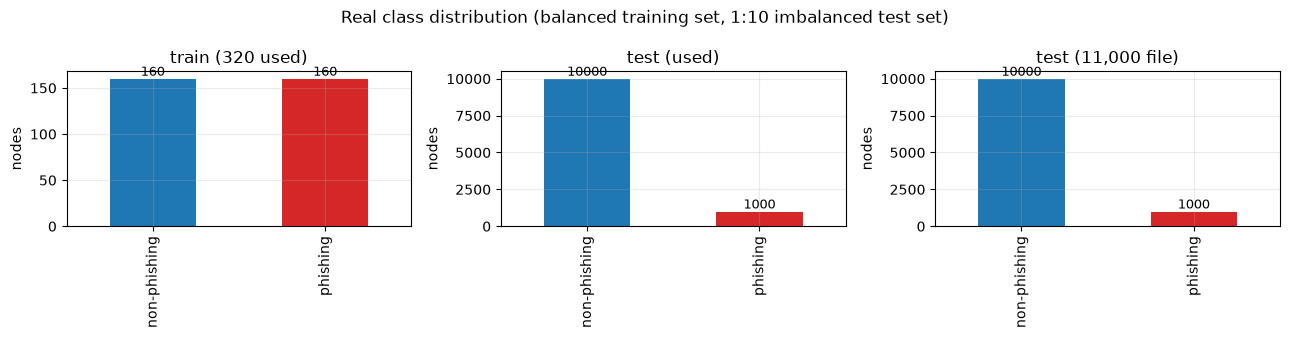

In [5]:
# ---- (a) shape, feature names, original label values, class counts, bar chart ----
print("Training set:", X_tr.shape, "| test set:", X_te.shape, "| features:", FEATURES)
print("Original label files are one-hot ([1, 0] = phishing, [0, 1] = non-phishing); decoded values:", sorted(LABEL_NAMES.items()))
cnt = pd.DataFrame({
    "train (320 used)":  pd.Series(y_tr).map(LABEL_NAMES).value_counts(),
    "train (960 file)":  pd.Series(ytr_all).map(LABEL_NAMES).value_counts(),
    "test (used)":       pd.Series(y_te).map(LABEL_NAMES).value_counts(),
    "test (11,000 file)": pd.Series(yte_all).map(LABEL_NAMES).value_counts()})
display(cnt)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for a, col in zip(ax, ["train (320 used)", "test (used)", "test (11,000 file)"]):
    cnt[col].reindex(["non-phishing", "phishing"]).plot.bar(ax=a, color=["tab:blue", "tab:red"])
    a.set_title(col); a.set_ylabel("nodes")
    for p in a.patches: a.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=9)
plt.suptitle("Real class distribution (balanced training set, 1:10 imbalanced test set)"); plt.tight_layout(); plt.show()

In [6]:
# ---- (b) per-class feature statistics of the real nodes ----
full_te = pd.DataFrame(Xte_all, columns=FEATURES)
st = pd.concat({"test phishing (1,000): mean": full_te[yte_all == 1].mean(), "test non-phishing (10,000): mean": full_te[yte_all == 0].mean(),
                "test phishing: median": full_te[yte_all == 1].median(), "test non-phishing: median": full_te[yte_all == 0].median(),
                "train phishing (160): mean": pd.DataFrame(X_tr[y_tr == 1], columns=FEATURES).mean(),
                "train non-phishing (160): mean": pd.DataFrame(X_tr[y_tr == 0], columns=FEATURES).mean()}, axis=1)
display(st.round(2))

,"test phishing (1,000): mean","test non-phishing (10,000): mean",test phishing: median,test non-phishing: median,train phishing (160): mean,train non-phishing (160): mean
in_degree,29.13,4.75,9.00,0.00,45.54,0.57
out_degree,19.57,4.79,2.00,1.00,26.22,1.84
degree,48.71,9.54,12.00,1.00,71.76,2.41
in_strength,84.15,77.79,7.60,0.00,43.97,2.27
out_strength,94.71,9.53,6.06,0.00,36.91,6.34
strength,178.86,87.32,14.70,0.01,80.88,8.61
n_neighbors,29.52,3.79,10.00,1.00,45.28,1.49


PCA explained variance ratio (train fit): [0.736 0.132]


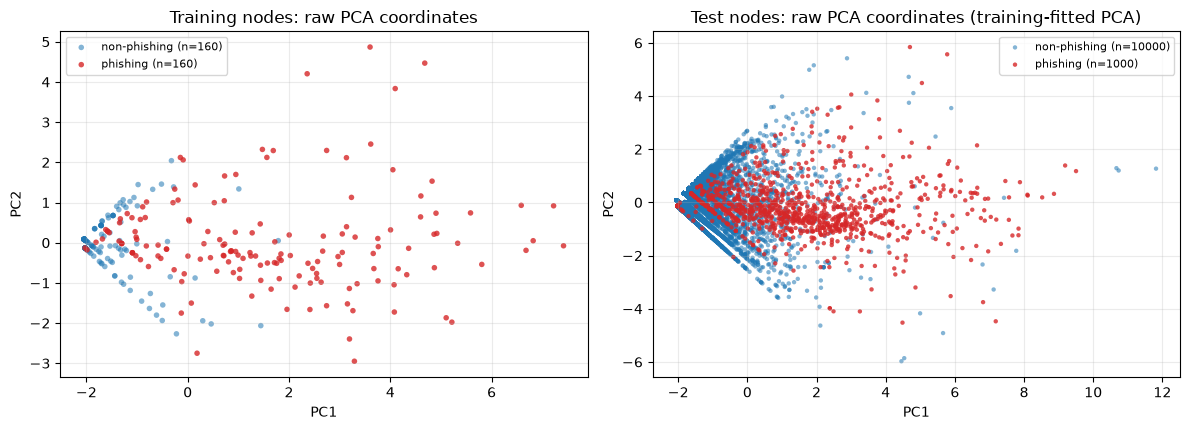

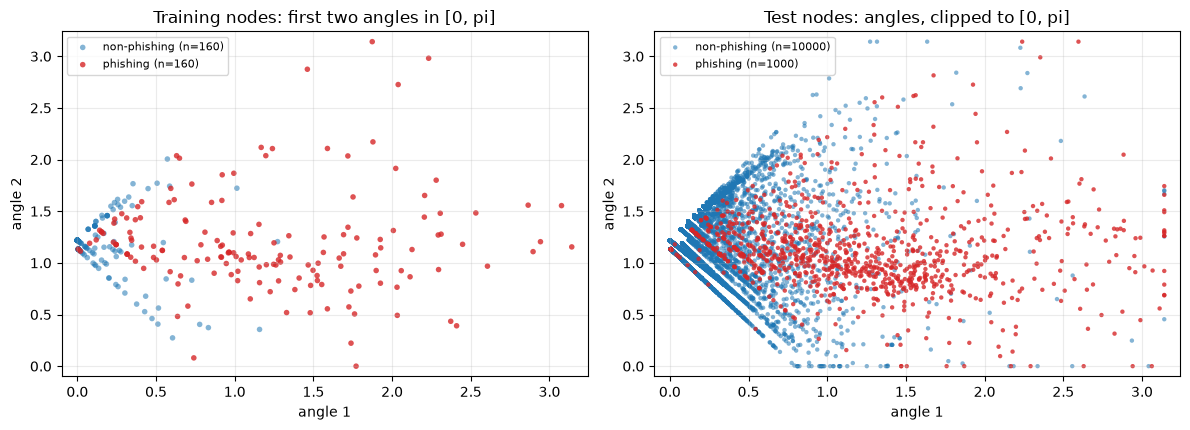

In [7]:
# ---- (c) 2-D scatter of real nodes coloured by ground truth: raw PCA coordinates, then angles in [0, pi] ----
# CHOICE: log1p first (degrees and strengths span 5 orders of magnitude); every transform is fitted on the training split only.
sc_pca = StandardScaler().fit(np.log1p(X_tr)); pca2 = PCA(n_components=2, random_state=SEED).fit(sc_pca.transform(np.log1p(X_tr)))
P_tr = pca2.transform(sc_pca.transform(np.log1p(X_tr))); P_te = pca2.transform(sc_pca.transform(np.log1p(X_te)))
ang = MinMaxScaler((0, np.pi)).fit(P_tr)
A_tr = ang.transform(P_tr); A_te = np.clip(ang.transform(P_te), 0, np.pi)
print("PCA explained variance ratio (train fit):", pca2.explained_variance_ratio_.round(3))

COL = {0: "tab:blue", 1: "tab:red"}
def scatter(ax, P, y, title, xl, yl, s=10):
    for c in (0, 1):
        m = y == c
        ax.scatter(P[m, 0], P[m, 1], s=s, c=COL[c], alpha=0.55 if c == 0 else 0.8, label=f"{LABEL_NAMES[c]} (n={int(m.sum())})", edgecolors="none")
    ax.set_title(title); ax.set_xlabel(xl); ax.set_ylabel(yl); ax.legend(fontsize=8)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
scatter(ax[0], P_tr, y_tr, "Training nodes: raw PCA coordinates", "PC1", "PC2", s=16)
scatter(ax[1], P_te, y_te, "Test nodes: raw PCA coordinates (training-fitted PCA)", "PC1", "PC2")
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
scatter(ax[0], A_tr, y_tr, "Training nodes: first two angles in [0, pi]", "angle 1", "angle 2", s=16)
scatter(ax[1], A_te, y_te, "Test nodes: angles, clipped to [0, pi]", "angle 1", "angle 2")
for a in ax: a.set_xlim(-0.1, np.pi + 0.1); a.set_ylim(-0.1, np.pi + 0.1)
plt.tight_layout(); plt.show()

## 2. Preprocessing and the data encodings

All encodings start from the same 320 training nodes (statistics such as medians, cut-offs, minima and maxima come from the training
split only). Eight encodings are built:

* **`Z-raw`, `ZZ-raw`, `ZZ-scaled`, `AE-raw`**: real-valued features. `ZZ-raw` and `Z-raw` feed the raw features into the angles (as
  the authors do); `ZZ-scaled` uses `log1p` features min-max scaled to [0, pi]; `AE-raw` is amplitude encoding of the 7 raw features
  (padded to 8 amplitudes, 3 qubits).
* **`QRAC-3q(3,1)`, `QRAC-2q(3,1)`**: every feature is compared with its **median** (above -> `1`), the seven bits are grouped as
  `[in-deg, out-deg, deg]`, `[in-str, out-str, str]`, `[n-neighbours, 0, 0]` and each 3-bit string is written into one qubit with one
  U3 gate (Table I). With three qubits there is one QRAC per qubit; with two qubits the third QRAC is **concatenated** onto qubit 1.
* **`QRAC-cat(2,1)`, `QRAC-cat(3,1)`**: three features (degree, strength, number of neighbours), each cut into 4 categories at 3
  cut-offs; the category is mapped to a 2-bit string and a (2,1)-QRAC state, or to one of the four diagonal corners
  `000, 101, 110, 011` of the (3,1)-QRAC cube.

The U3 angles are those printed in the paper (Table I). The cell below builds them and **asserts** that the 8 (3,1)-states have Bloch
vectors `(+-1,+-1,+-1)/sqrt(3)` (cube corners) and the 4 (2,1)-states Bloch vectors `(+-1,0,+-1)/sqrt(2)` (square corners), so any
typo would stop the notebook.

(3,1)-QRAC: 8 distinct Bloch vectors (+-1,+-1,+-1)/sqrt(3); bit-recovery probability = 0.789  (paper: 0.78)
(2,1)-QRAC: 4 distinct Bloch vectors (+-1,0,+-1)/sqrt(2);   bit-recovery probability = 0.854  (paper: 0.85)
distances between the four categorised (3,1) corners: [1.633 1.633 1.633 1.633 1.633 1.633] (all equal: a tetrahedron inscribed in the cube)


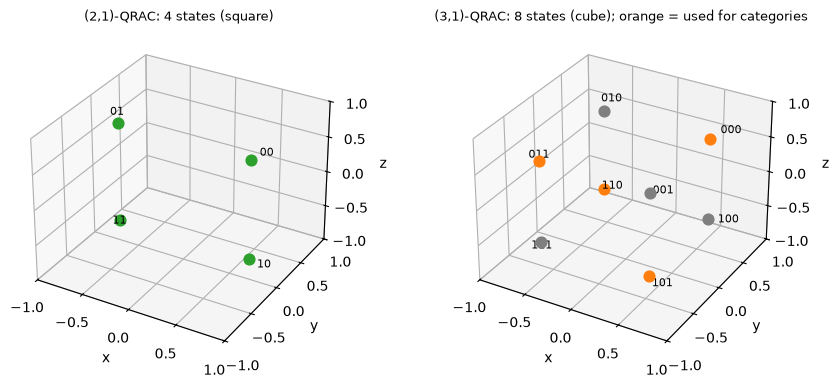

In [8]:
# ---------------- QRAC angle tables ----------------
THETA = np.arccos(np.sqrt(0.5 + np.sqrt(3) / 6))
def qrac31_angles(b1, b2, b3):
    """U3(theta, phi, lambda) for a 3-bit string, paper Table I."""
    th = 2 * THETA if b1 == 0 else np.pi - 2 * THETA
    base = np.pi / 4 if b2 == 0 else 3 * np.pi / 4
    phi = base if b3 == 0 else -base
    return (th, phi, -phi)
QRAC21 = {(0, 0): np.pi / 4, (1, 0): 3 * np.pi / 4, (1, 1): 5 * np.pi / 4, (0, 1): 7 * np.pi / 4}   # paper: '00','10','11','01'
def u3_state(th, ph, la):
    return Statevector([np.cos(th / 2), np.exp(1j * ph) * np.sin(th / 2)])      # U3(th, ph, la)|0>
def bloch(sv):
    p = sv.data; return np.real([np.conj(p) @ (m @ p) for m in (np.array([[0, 1], [1, 0]]), np.array([[0, -1j], [1j, 0]]), np.diag([1., -1.]))])

B31 = {b: bloch(u3_state(*qrac31_angles(*b))) for b in np.ndindex(2, 2, 2)}
for b, v in B31.items():
    assert np.allclose(np.abs(v), 1 / np.sqrt(3), atol=1e-9), (b, v)
assert len({tuple(np.round(v, 6)) for v in B31.values()}) == 8
B21 = {b: bloch(u3_state(QRAC21[b], 0, 0)) for b in QRAC21}
for b, v in B21.items():
    assert np.allclose(np.abs(v[[0, 2]]), 1 / np.sqrt(2), atol=1e-9) and abs(v[1]) < 1e-9, (b, v)
print(f"(3,1)-QRAC: 8 distinct Bloch vectors (+-1,+-1,+-1)/sqrt(3); bit-recovery probability = {0.5 + 0.5 / np.sqrt(3):.3f}  (paper: 0.78)")
print(f"(2,1)-QRAC: 4 distinct Bloch vectors (+-1,0,+-1)/sqrt(2);   bit-recovery probability = {0.5 + 0.5 / np.sqrt(2):.3f}  (paper: 0.85)")

# the four corners used for the categorised (3,1)-QRAC: pairwise distances show they are as far apart as the cube allows
CAT31_BITS = [(0, 0, 0), (1, 0, 1), (1, 1, 0), (0, 1, 1)]
d = [np.linalg.norm(B31[a] - B31[b]) for i, a in enumerate(CAT31_BITS) for b in CAT31_BITS[i + 1:]]
print("distances between the four categorised (3,1) corners:", np.round(d, 3), "(all equal: a tetrahedron inscribed in the cube)")
CAT21_BITS = [(0, 0), (0, 1), (1, 0), (1, 1)]

fig = plt.figure(figsize=(9, 4))
a1 = fig.add_subplot(1, 2, 1, projection="3d"); a2 = fig.add_subplot(1, 2, 2, projection="3d")
for b, v in B21.items(): a1.scatter(*v, s=60, c="tab:green"); a1.text(*(v * 1.12), "".join(map(str, b)), fontsize=8)
for b, v in B31.items(): a2.scatter(*v, s=60, c="tab:orange" if b in CAT31_BITS else "tab:gray"); a2.text(*(v * 1.12), "".join(map(str, b)), fontsize=8)
for a, t in ((a1, "(2,1)-QRAC: 4 states (square)"), (a2, "(3,1)-QRAC: 8 states (cube); orange = used for categories")):
    a.set_xlim(-1, 1); a.set_ylim(-1, 1); a.set_zlim(-1, 1); a.set_title(t, fontsize=9); a.set_xlabel("x"); a.set_ylabel("y"); a.set_zlabel("z")
plt.tight_layout(); plt.show()

In [9]:
# ---------------- feature-map circuits: binarised QRAC schemes (U3 gates, symbolic inputs) ----------------
# layout[q] is the list of U3 gates on qubit q: bit-index triple into the 8-column bit matrix (column 7 is a constant-0 pad)
SCHEMES = {
    "QRAC-3q(3,1)": {"n": 3, "layout": [[(0, 1, 2)], [(3, 4, 5)], [(6, 7, 7)]]},
    "QRAC-2q(3,1)": {"n": 2, "layout": [[(0, 1, 2), (6, 7, 7)], [(3, 4, 5)]]},   # CHOICE: third string concatenated on qubit 1
}
def qrac_feature_map(scheme, name=None):
    spec = SCHEMES[scheme]; n_gates = sum(len(g) for g in spec["layout"])
    x = ParameterVector("x", 3 * n_gates); qc = QuantumCircuit(spec["n"], name=name or scheme); k = 0
    for q, gates in enumerate(spec["layout"]):
        for _ in gates:
            qc.u(x[3 * k], x[3 * k + 1], x[3 * k + 2], q); k += 1
    return qc

def qrac_angles(bits, scheme):
    """(n_nodes, 7) bit matrix -> (n_nodes, 3 * n_gates) U3 angle matrix in the circuit's parameter order."""
    b8 = np.c_[bits, np.zeros(len(bits), dtype=int)]
    cols = []
    for gates in SCHEMES[scheme]["layout"]:
        for idx in gates:
            cols.append(np.array([qrac31_angles(*b8[i, list(idx)]) for i in range(len(b8))]))
    return np.concatenate(cols, axis=1)

# categorised schemes: 3 features -> 3 qubits, one U3 per qubit (feature order: degree, strength, n_neighbors)
CAT_FEATS = [2, 5, 6]
def cat_cutoffs(Xtrain):
    cuts = []
    for j in CAT_FEATS:
        if FEATURES[j] == "degree":
            c = np.array([10., 20., 100.])                                   # paper: 10, 20, 100 (feature no. 3)
        else:                                                                # CHOICE: training-split quantiles 50 / 75 / 90 %
            c = np.quantile(Xtrain[:, j], [0.5, 0.75, 0.9])
            for k in range(1, 3): c[k] = max(c[k], np.nextafter(c[k - 1], np.inf))   # strictly increasing
        cuts.append(c)
    return cuts
CUTS = cat_cutoffs(X_tr)
def cat_codes(X, cuts=None):
    cuts = CUTS if cuts is None else cuts
    return np.stack([np.searchsorted(c, np.asarray(X)[:, j], side="right") for c, j in zip(cuts, CAT_FEATS)], axis=1)   # 0..3
def cat_angles(X, kind):
    codes = cat_codes(X); out = np.zeros((len(codes), 9))
    for q in range(3):
        for i, c in enumerate(codes[:, q]):
            out[i, 3 * q:3 * q + 3] = (QRAC21[CAT21_BITS[c]], 0.0, 0.0) if kind == 21 else qrac31_angles(*CAT31_BITS[c])
    return out
def cat_feature_map(name):
    x = ParameterVector("x", 9); qc = QuantumCircuit(3, name=name)
    for q in range(3): qc.u(x[3 * q], x[3 * q + 1], x[3 * q + 2], q)
    return qc
print("categorisation cut-offs (degree, strength, n_neighbors):", [np.round(c, 3).tolist() for c in CUTS])
print("category shares in the training split (columns = categories 0..3):")
display(pd.DataFrame([np.bincount(cat_codes(X_tr)[:, q], minlength=4) for q in range(3)], index=[FEATURES[j] for j in CAT_FEATS]))

# executed-state check: the 3-qubit scheme applied to a known bit string gives the product of the three single-qubit states
fm_chk = qrac_feature_map("QRAC-3q(3,1)")
bits_chk = np.array([[0, 1, 1, 0, 1, 0, 1]])                                 # the paper's example point -> strings 011 | 010 | 100
st_ = Statevector(fm_chk.assign_parameters(qrac_angles(bits_chk, "QRAC-3q(3,1)")[0]))
ref = u3_state(*qrac31_angles(1, 0, 0)).tensor(u3_state(*qrac31_angles(0, 1, 0))).tensor(u3_state(*qrac31_angles(0, 1, 1)))
assert abs(abs(np.vdot(ref.data, st_.data)) - 1) < 1e-9
print("paper example [0,1,1,0,1,0,1] -> strings 011 | 010 | 100 : feature-map state equals the product of the three QRAC states.")

categorisation cut-offs (degree, strength, n_neighbors): [[10.0, 20.0, 100.0], [1.077, 21.398, 90.885], [2.0, 11.0, 43.1]]
category shares in the training split (columns = categories 0..3):


,0,1,2,3
degree,218,28,52,22
strength,160,80,48,32
n_neighbors,134,102,52,32


paper example [0,1,1,0,1,0,1] -> strings 011 | 010 | 100 : feature-map state equals the product of the three QRAC states.


### Building the encodings

`make_encoding(name, mode)` returns the feature-map circuit and a function `transform(X)` that turns raw nodes into the circuit's
parameter vector (for amplitude encoding: the normalised amplitude vector). **Every statistic (median, cut-off, min, max) comes from
the training split only**, except in the `[paper median]` ablation that follows the paper's wording.

In [10]:
def ae_vectors(X):
    A = np.zeros((len(X), 8)); A[:, :7] = np.asarray(X, float)
    nrm = np.linalg.norm(A, axis=1, keepdims=True); A = np.where(nrm > 0, A / np.where(nrm > 0, nrm, 1), np.eye(8)[0])
    return A
def ae_circuit(amps):
    qc = QuantumCircuit(3, name="AE"); qc.append(StatePreparation(np.asarray(amps, complex)), [0, 1, 2]); return qc

def make_encoding(name, mode="train"):
    thr = np.median(X_tr, axis=0) if mode == "train" else np.median(np.vstack([X_tr, Xte_all]), axis=0)
    if name == "ZZ-raw":
        fm = zz_feature_map(7, reps=2, entanglement="full", parameter_prefix="x"); tf = lambda X: np.asarray(X, float)
    elif name == "ZZ-scaled":
        fm = zz_feature_map(7, reps=2, entanglement="full", parameter_prefix="x")
        mm = MinMaxScaler((0, np.pi)).fit(np.log1p(X_tr)); tf = lambda X, mm=mm: np.clip(mm.transform(np.log1p(X)), 0, np.pi)
    elif name == "Z-raw":
        fm = z_feature_map(7, reps=2, parameter_prefix="x"); tf = lambda X: np.asarray(X, float)
    elif name == "AE-raw":
        fm = ae_circuit(ae_vectors(X_tr[:1])[0]); tf = ae_vectors                 # template circuit (bound to one node), for drawing
    elif name in SCHEMES:
        fm = qrac_feature_map(name); tf = lambda X, thr=thr, name=name: qrac_angles((np.asarray(X) > thr).astype(int), name)
    elif name == "QRAC-cat(2,1)":
        fm = cat_feature_map(name); tf = lambda X: cat_angles(X, 21)
    elif name == "QRAC-cat(3,1)":
        fm = cat_feature_map(name); tf = lambda X: cat_angles(X, 31)
    else: raise ValueError(name)
    return {"name": name, "mode": mode, "fm": fm, "n": fm.num_qubits, "tf": tf}

ENCODINGS = ["ZZ-raw", "ZZ-scaled", "Z-raw", "AE-raw", "QRAC-3q(3,1)", "QRAC-2q(3,1)", "QRAC-cat(2,1)", "QRAC-cat(3,1)"]
ENC = {(n, "train"): make_encoding(n, "train") for n in ENCODINGS}
for m in BIN_MODES:
    if m != "train":
        for n in ("QRAC-3q(3,1)", "QRAC-2q(3,1)"): ENC[(n, m)] = make_encoding(n, m)
THR_TRAIN = np.median(X_tr, axis=0); THR_PAPER = np.median(np.vstack([X_tr, Xte_all]), axis=0)
print(pd.DataFrame({"median (train split)": THR_TRAIN, "median (train + test, paper-literal)": THR_PAPER}, index=FEATURES).round(3))
for k, e in ENC.items():
    if k[1] == "train":
        print(f"{k[0]:14s} qubits={e['n']}  input parameters={e['fm'].num_parameters if k[0] != 'AE-raw' else 8:2d} "
              f"({'amplitudes' if k[0] == 'AE-raw' else 'angles'})  feature-map depth={e['fm'].decompose().decompose().decompose().depth()}")
print(f"qubit compression: ZZ/Z map {ENC[('ZZ-raw','train')]['n']} qubits -> QRAC {ENC[('QRAC-2q(3,1)','train')]['n']} qubits = "
      f"{ENC[('ZZ-raw','train')]['n'] / ENC[('QRAC-2q(3,1)','train')]['n']:.1f}x (paper: 3.5x)")

              median (train split)  median (train + test, paper-literal)
in_degree                    1.000                                 0.000
out_degree                   1.000                                 1.000
degree                       3.000                                 1.000
in_strength                  0.244                                 0.000
out_strength                 0.054                                 0.000
strength                     1.077                                 0.039
n_neighbors                  2.000                                 1.000


ZZ-raw         qubits=7  input parameters= 7 (angles)  feature-map depth=58
ZZ-scaled      qubits=7  input parameters= 7 (angles)  feature-map depth=58
Z-raw          qubits=7  input parameters= 7 (angles)  feature-map depth=4
AE-raw         qubits=3  input parameters= 8 (amplitudes)  feature-map depth=9
QRAC-3q(3,1)   qubits=3  input parameters= 9 (angles)  feature-map depth=1
QRAC-2q(3,1)   qubits=2  input parameters= 9 (angles)  feature-map depth=2
QRAC-cat(2,1)  qubits=3  input parameters= 9 (angles)  feature-map depth=1
QRAC-cat(3,1)  qubits=3  input parameters= 9 (angles)  feature-map depth=1
qubit compression: ZZ/Z map 7 qubits -> QRAC 2 qubits = 3.5x (paper: 3.5x)


distinct 7-bit patterns: train 39 (of 320 nodes), test 72 (of 11000); max possible 128


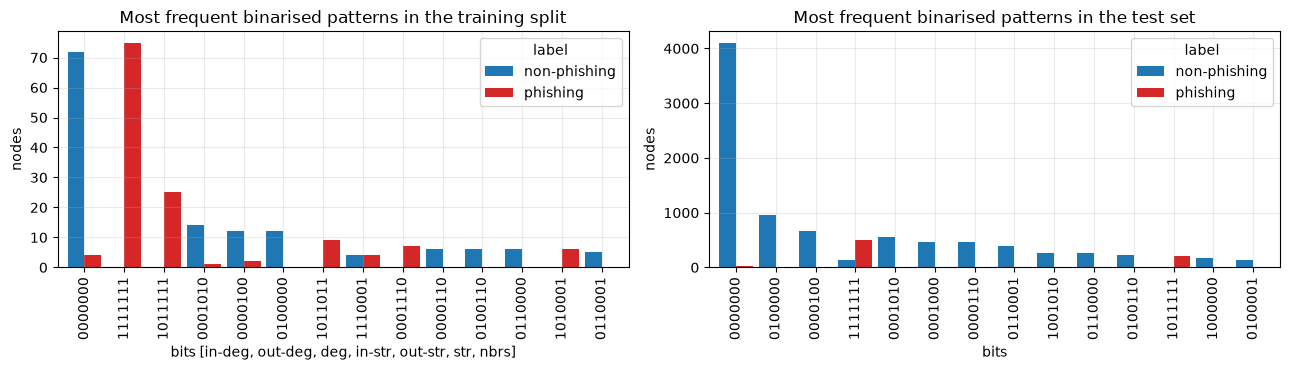

In [11]:
# ---- what the QRAC bit patterns look like for real nodes: 7 bits -> at most 128 distinct inputs ----
bits_tr = (X_tr > THR_TRAIN).astype(int); bits_te = (X_te > THR_TRAIN).astype(int)
pat = lambda B: pd.Series(["".join(map(str, r)) for r in B])
d = pd.DataFrame({"pattern": pat(bits_tr), "label": pd.Series(y_tr).map(LABEL_NAMES)})
top = d.groupby(["pattern", "label"]).size().unstack(fill_value=0)
top["total"] = top.sum(1); top = top.sort_values("total", ascending=False).head(14)
print(f"distinct 7-bit patterns: train {pat(bits_tr).nunique()} (of 320 nodes), test {pat(bits_te).nunique()} (of {len(bits_te)}); max possible 128")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
top[["non-phishing", "phishing"]].plot.bar(ax=ax[0], color=["tab:blue", "tab:red"], width=0.85)
ax[0].set_title("Most frequent binarised patterns in the training split"); ax[0].set_xlabel("bits [in-deg, out-deg, deg, in-str, out-str, str, nbrs]"); ax[0].set_ylabel("nodes")
dd = pd.DataFrame({"pattern": pat(bits_te), "label": pd.Series(y_te).map(LABEL_NAMES)}).groupby(["pattern", "label"]).size().unstack(fill_value=0)
dd["total"] = dd.sum(1); dd = dd.sort_values("total", ascending=False).head(14)
dd[["non-phishing", "phishing"]].plot.bar(ax=ax[1], color=["tab:blue", "tab:red"], width=0.85)
ax[1].set_title("Most frequent binarised patterns in the test set"); ax[1].set_xlabel("bits"); ax[1].set_ylabel("nodes")
plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

The circuits below are the objects that are actually simulated later: the same `QuantumCircuit` instances are passed to
`Statevector` (QSVM kernels) and `EstimatorQNN` (VQC checks); the fast NumPy routines of Section 3 are **asserted equal** to them.
Each VQC circuit is `feature map -> ansatz`, and its read-out is the parity of the measured bit string, which is the expectation value of
`Z x ... x Z`; a cell asserts that this expectation equals the parity computed from the measurement probabilities, and the figures
append the measurements. The QSVM kernel circuit is the compute-uncompute circuit `phi(x_j)^dagger phi(x_i)` of the paper's Eq. 4-6.

**Assumptions where the paper omits circuit details**: the VQC ansatz of Table II (`ry`, `rz` rotations, `cz` entanglers, `full`
entanglement, 2 repetitions, final rotation layer: the authors' repository choice), the exact form of the 19 benchmark ansatzes (Sim et
al. 2019, one layer, drawn below), the placement of the third (3,1)-QRAC on qubit 1 for the 2-qubit scheme, the ZZ-map repetitions (2)
and the amplitude-encoding state preparation. The annealing QSVM is a QUBO, not a gate circuit, and has no drawing (Section 7).

In [12]:
# ---------------- the 19 benchmark ansatzes (Sim, Johnson, Aspuru-Guzik 2019, Fig. 2) ----------------
# CHOICE: re-implemented from the published description, one layer; gate order inside entangling blocks may differ from the authors' code.
def sim_ansatz(k, n):
    qc = QuantumCircuit(n, name=f"ansatz {k}"); P = []
    def par():
        p = Parameter(f"w{len(P):03d}"); P.append(p); return p
    def rot(gates, qubits=None):
        for q in (range(n) if qubits is None else qubits):
            for g in gates: getattr(qc, g)(par(), q)
    two = {"cx": lambda c, t: qc.cx(c, t), "cz": lambda c, t: qc.cz(c, t), "crz": lambda c, t: qc.crz(par(), c, t), "crx": lambda c, t: qc.crx(par(), c, t)}
    def ladder(g):
        for i in reversed(range(n - 1)): two[g](i + 1, i)
    def ring(g, shift=False):
        order = [(i, (i + 1) % n) for i in reversed(range(n))] if not shift else [(i, (i - 1) % n) for i in reversed(range(n))]
        for c, t in order:
            if c != t: two[g](c, t)
    def alltoall(g):
        for i in reversed(range(n)):
            for j in reversed(range(n)):
                if i != j: two[g](i, j)
    def brick(g, parity):
        for i in range(parity, n - 1, 2): two[g](i, i + 1)
    inner = list(range(1, n - 1))
    if k == 1: rot(["rx", "rz"])
    elif k in (2, 3, 4): rot(["rx", "rz"]); ladder({2: "cx", 3: "crz", 4: "crx"}[k])
    elif k in (5, 6): rot(["rx", "rz"]); alltoall({5: "crz", 6: "crx"}[k]); rot(["rx", "rz"])
    elif k in (7, 8): g = {7: "crz", 8: "crx"}[k]; rot(["rx", "rz"]); brick(g, 0); rot(["rx", "rz"]); brick(g, 1)
    elif k == 9: [qc.h(q) for q in range(n)]; ladder("cz"); rot(["rx"])
    elif k == 10: rot(["ry"]); ring("cz"); rot(["ry"])
    elif k in (11, 12): g = {11: "cx", 12: "cz"}[k]; rot(["ry", "rz"]); brick(g, 0); rot(["ry", "rz"], inner); brick(g, 1)
    elif k in (13, 14): g = {13: "crz", 14: "crx"}[k]; rot(["ry"]); ring(g); rot(["ry"]); ring(g, shift=True)
    elif k == 15: rot(["ry"]); ring("cx"); rot(["ry"]); ring("cx", shift=True)
    elif k in (16, 17): g = {16: "crz", 17: "crx"}[k]; rot(["rx", "rz"]); brick(g, 0); rot(["rx", "rz"], inner); brick(g, 1)
    elif k in (18, 19): rot(["rx", "rz"]); ring({18: "crz", 19: "crx"}[k])
    else: raise ValueError(k)
    qc._plist = P
    return qc

def main_ansatz(n):
    return n_local(n, ["ry", "rz"], "cz", entanglement="full", reps=2, parameter_prefix="w").decompose()   # CHOICE: authors' TwoLocal(['ry','rz'],'cz',reps=2)

def plist(ans):
    return list(getattr(ans, "_plist", None) or ans.parameters)

def unitary(ans, w):
    return Operator(ans.assign_parameters(dict(zip(plist(ans), w)))).data

rows = [{"ansatz": k, "qubits(3)": 3, "params(3q)": len(sim_ansatz(k, 3)._plist), "params(7q)": len(sim_ansatz(k, 7)._plist),
         "depth(3q)": sim_ansatz(k, 3).decompose().depth(), "2-qubit gates(7q)": sum(v for g, v in sim_ansatz(k, 7).count_ops().items() if g in ("cx", "cz", "crx", "crz"))} for k in range(1, 20)]
display(pd.DataFrame(rows).set_index("ansatz").T)

ansatz,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
qubits(3),3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3
params(3q),6,6,8,8,18,18,14,14,3,6,8,8,12,12,6,10,10,9,9
params(7q),14,14,20,20,70,70,34,34,7,14,24,24,28,28,14,30,30,21,21
depth(3q),2,4,9,13,24,28,11,15,7,9,6,9,24,32,8,11,15,14,16
2-qubit gates(7q),0,6,6,6,42,42,6,6,6,7,6,6,14,14,14,6,6,7,7


In [13]:
def show_circuit(c, title, **kw):
    fig = c.draw("mpl", **kw); fig.suptitle(title, fontsize=10, y=1.0); display(fig); plt.close(fig)

SIGNS = {n: np.array([1 - 2 * (bin(i).count("1") % 2) for i in range(2 ** n)], float) for n in (2, 3, 7)}

def bound_vqc_circuit(e, a, ans, w):
    """The circuit that is executed for ONE node: feature map bound to its angles, then the ansatz bound to the weights."""
    fmc = ae_circuit(a) if e["name"] == "AE-raw" else e["fm"].assign_parameters(a)
    qc = QuantumCircuit(e["n"]); qc.compose(fmc, inplace=True); qc.compose(ans.assign_parameters(dict(zip(plist(ans), w))), inplace=True)
    return qc

rows = []
for (name, mode), e in ENC.items():
    if mode != "train": continue
    ans = main_ansatz(e["n"]); full = e["fm"].decompose().decompose().decompose().compose(ans) if name != "AE-raw" else e["fm"].compose(ans)
    dec = full.decompose().decompose().decompose()
    rows.append({"encoding": name, "qubits": e["n"], "input angles": (e["fm"].num_parameters if name != "AE-raw" else 0), "trainable weights": len(plist(ans)),
                 "depth (VQC, decomposed)": dec.depth(), "2-qubit gates": dec.count_ops().get("cz", 0) + dec.count_ops().get("cx", 0)})
print("VQC circuits of Table II (feature map + n_local(ry,rz;cz;reps=2) ansatz):"); display(pd.DataFrame(rows))

# equivalence of the read-out: <Z x ... x Z> equals P(even) - P(odd) of the measured bit string, for a bound executed circuit
e = ENC[("QRAC-2q(3,1)", "train")]; ans = main_ansatz(e["n"]); w_chk = np.random.default_rng(SEED).uniform(0, 2 * np.pi, len(plist(ans)))
a_chk = e["tf"](X_te[:5]); par, ex = [], []
for a in a_chk:
    qc = bound_vqc_circuit(e, a, ans, w_chk); sv = Statevector(qc)
    p = sv.probabilities_dict()
    par.append(sum(v * (1 if bin(int(k, 2)).count("1") % 2 == 0 else -1) for k, v in p.items()))
    ex.append(sv.expectation_value(SparsePauliOp("Z" * e["n"])).real)
assert np.allclose(par, ex, atol=1e-8)
print("check: <Z..Z> of the executed circuit == P(even) - P(odd) of the measured bit string  ->", np.round(ex, 4))

VQC circuits of Table II (feature map + n_local(ry,rz;cz;reps=2) ansatz):


,encoding,qubits,input angles,trainable weights,"depth (VQC, decomposed)",2-qubit gates
0,ZZ-raw,7,7,42,101,126
1,ZZ-scaled,7,7,42,101,126
2,Z-raw,7,7,42,51,42
3,AE-raw,3,0,18,27,10
4,"QRAC-3q(3,1)",3,9,18,20,6
5,"QRAC-2q(3,1)",2,9,12,13,2
6,"QRAC-cat(2,1)",3,9,18,20,6
7,"QRAC-cat(3,1)",3,9,18,20,6


check: <Z..Z> of the executed circuit == P(even) - P(odd) of the measured bit string  -> [ 0.0647  0.1646 -0.5968  0.4582 -0.5244]


QSVM kernel circuit (3-qubit QRAC) for two training nodes: qubits=3, depth=3, trainable parameters=0 (kernel is non-parametric)


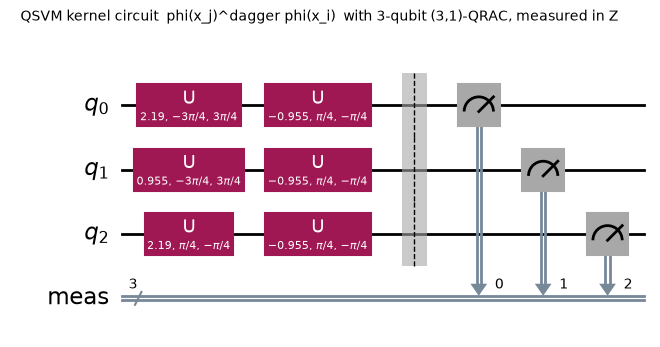

QRAC-3q(3,1): VQC circuit with 3 qubits | depth(decomposed)=21 | input angles=9 | trainable weights=18


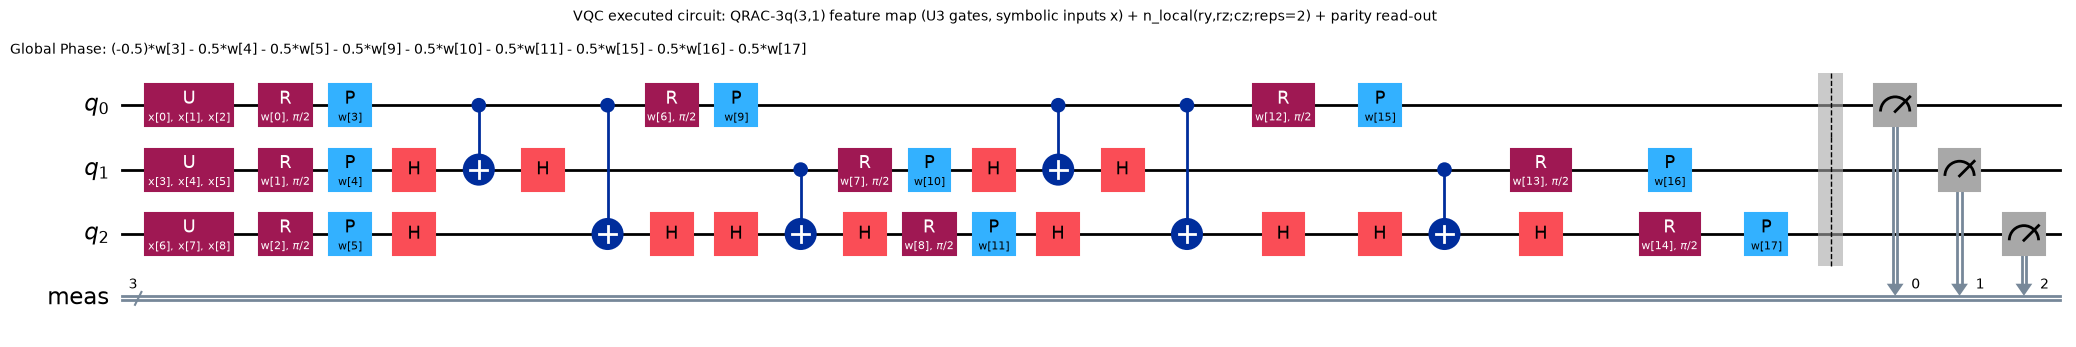

QRAC-2q(3,1): VQC circuit with 2 qubits | depth(decomposed)=14 | input angles=9 | trainable weights=12


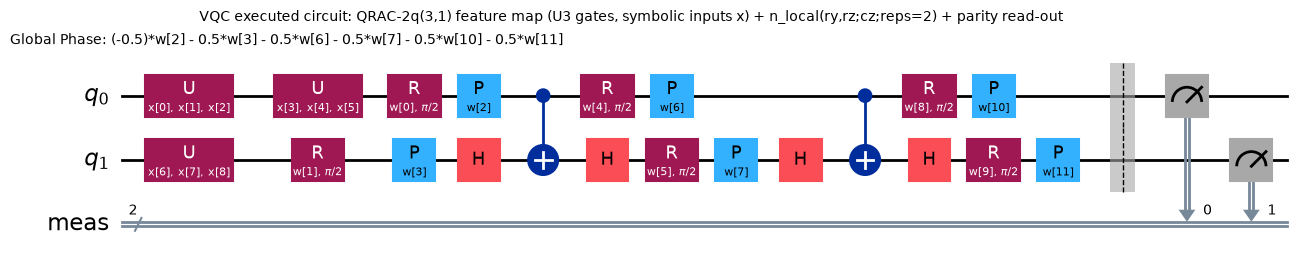

QRAC-cat(2,1): VQC circuit with 3 qubits | depth(decomposed)=21 | input angles=9 | trainable weights=18


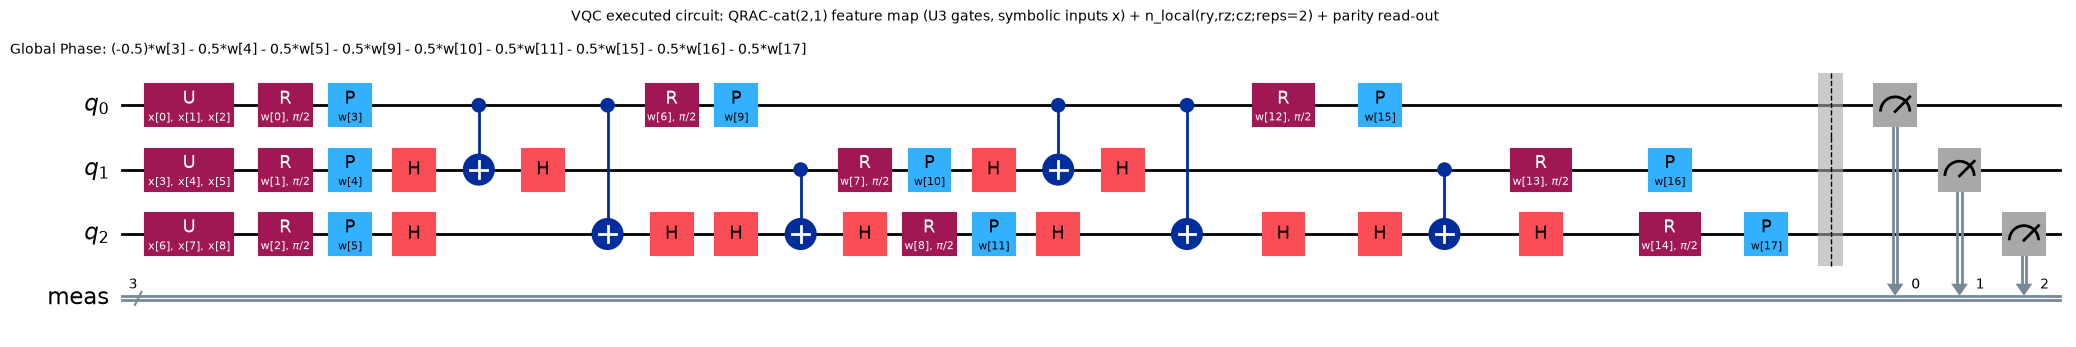

QRAC-cat(3,1): VQC circuit with 3 qubits | depth(decomposed)=21 | input angles=9 | trainable weights=18


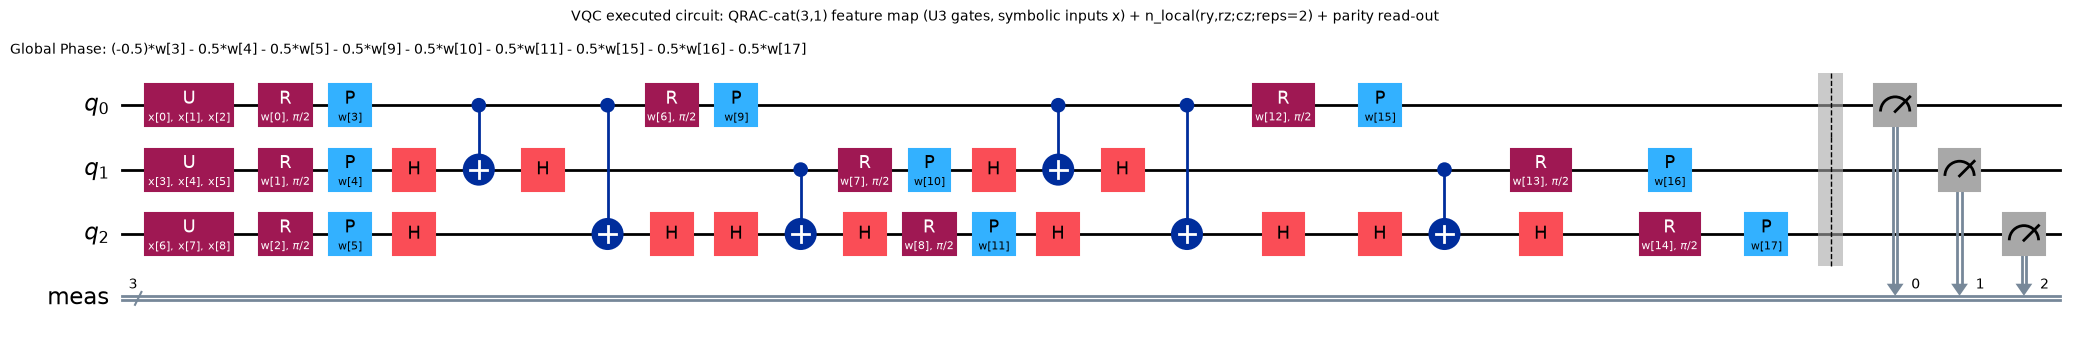

AE-raw: VQC circuit with 3 qubits | depth(decomposed)=23 | trainable weights=18 (state preparation bound to training node 3)


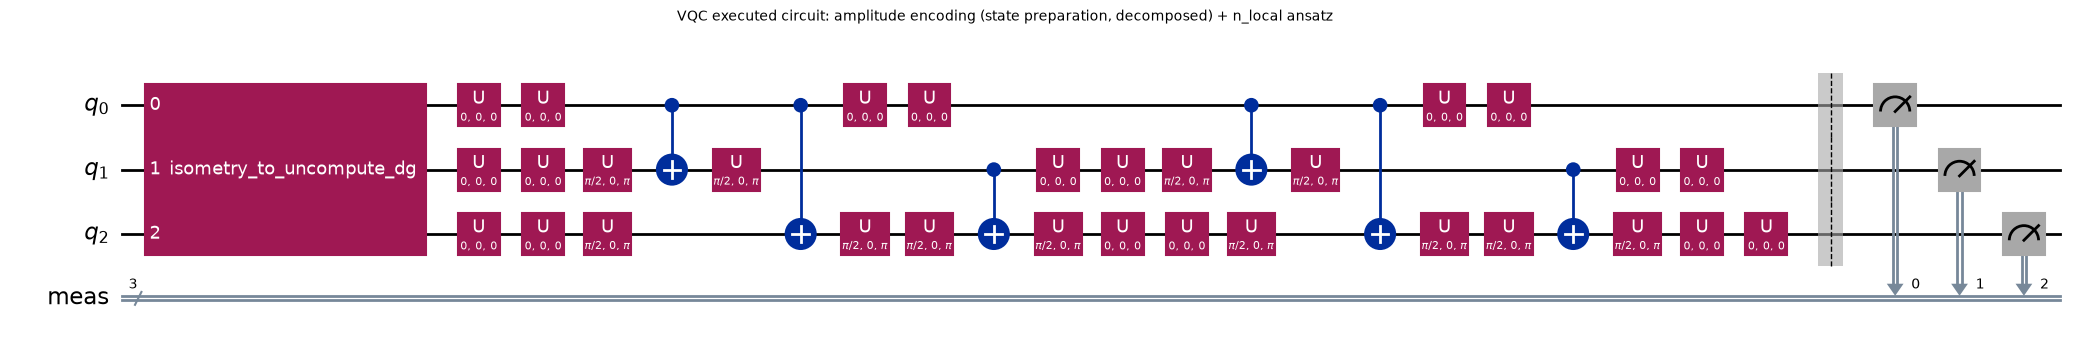

Z-raw-VQC: qubits=7 | depth(decomposed)=51 | input angles=7 | trainable weights=42 | entangling gates=42


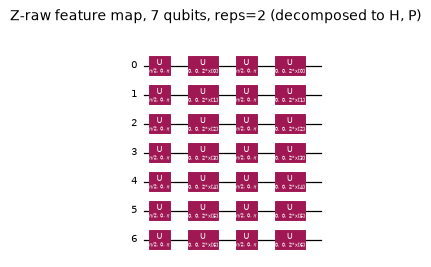

ZZ-raw-VQC: qubits=7 | depth(decomposed)=101 | input angles=7 | trainable weights=42 | entangling gates=126


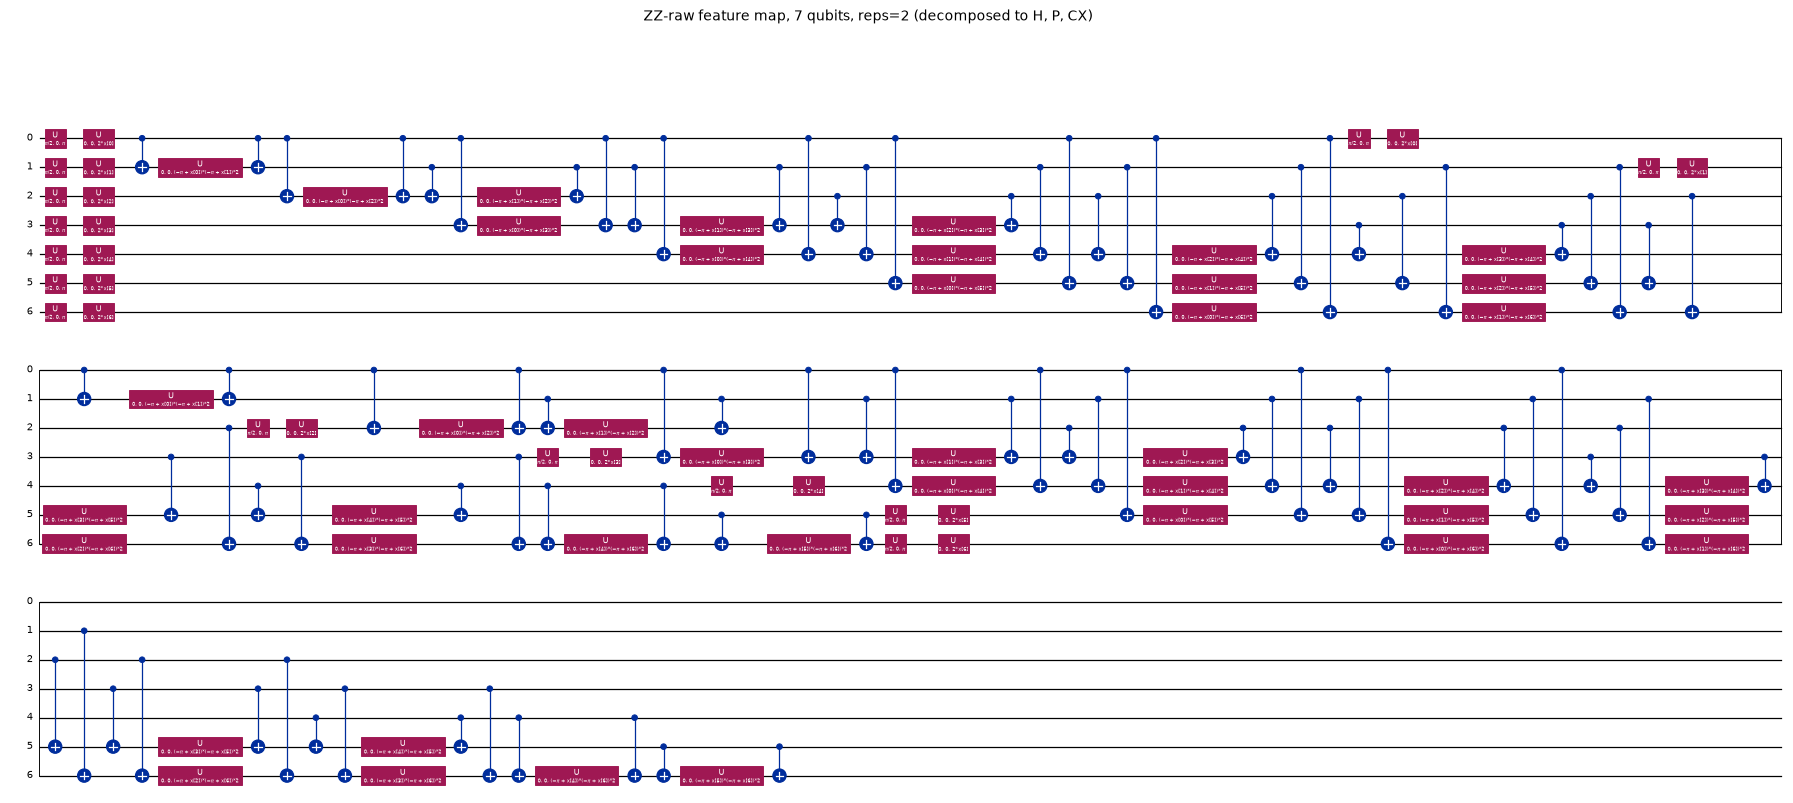

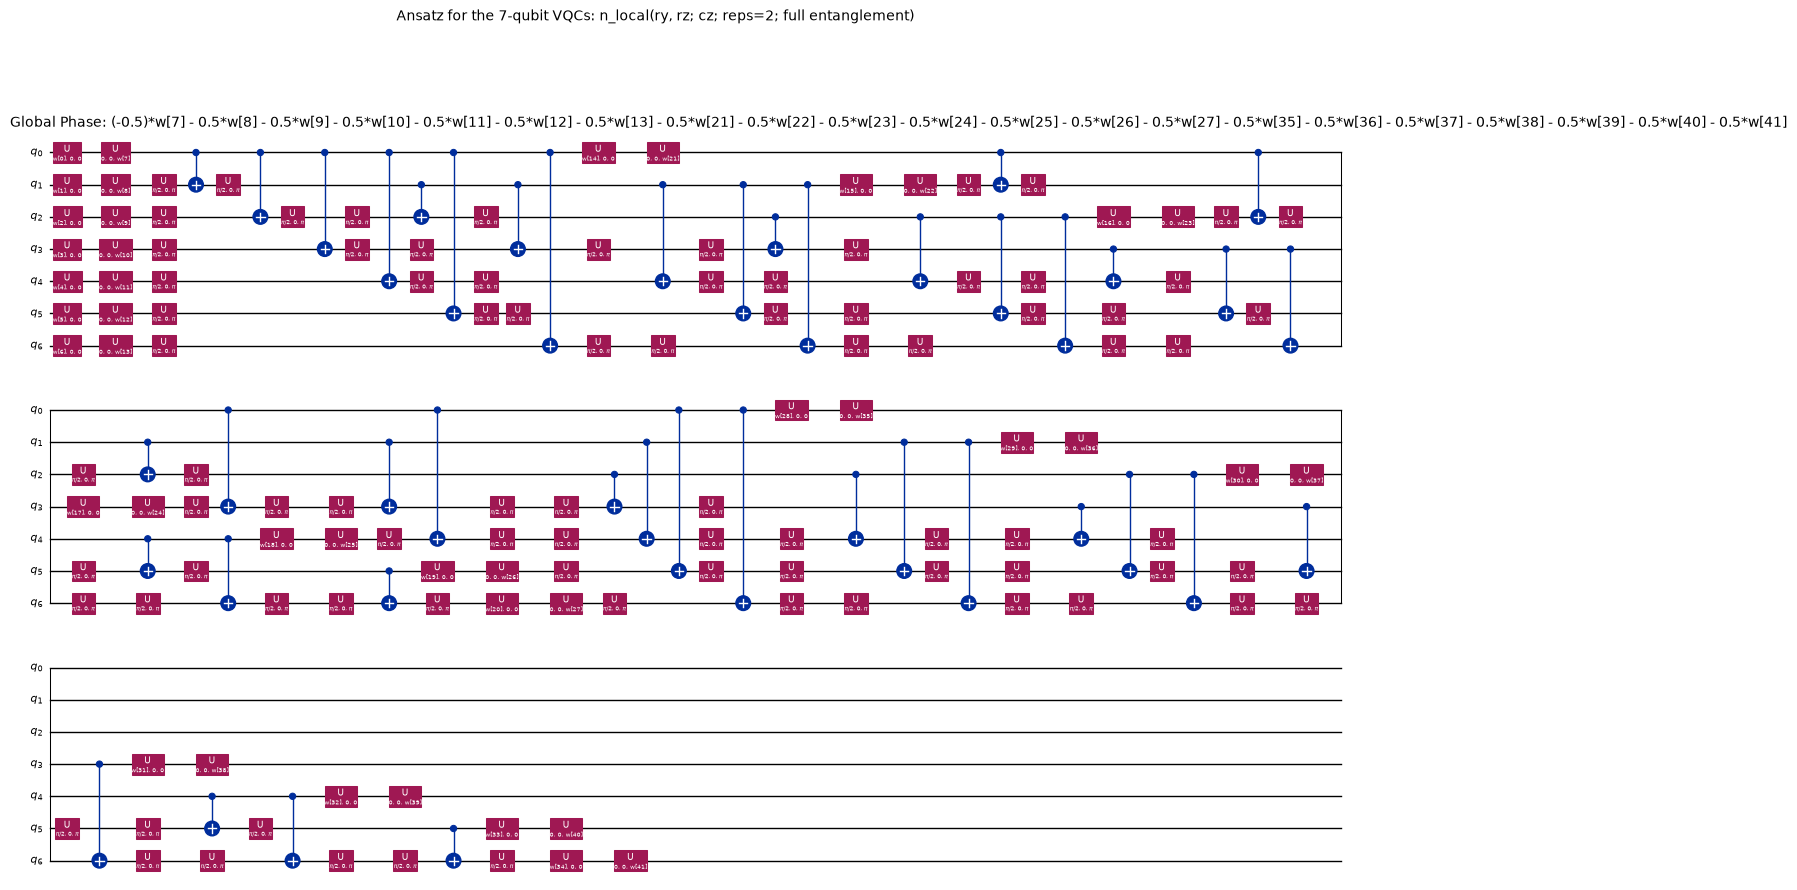

In [14]:
# ---- QSVM kernel circuit (compute-uncompute) and the VQC circuits of Table II, drawn from the objects used below ----
e3 = ENC[("QRAC-3q(3,1)", "train")]
xa, xb = e3["tf"](X_tr[[0, 200]])
kc = e3["fm"].assign_parameters(xa).compose(e3["fm"].assign_parameters(xb).inverse()); kc.measure_all()
print(f"QSVM kernel circuit (3-qubit QRAC) for two training nodes: qubits={kc.num_qubits}, depth={kc.decompose().depth()}, trainable parameters=0 (kernel is non-parametric)")
show_circuit(kc, "QSVM kernel circuit  phi(x_j)^dagger phi(x_i)  with 3-qubit (3,1)-QRAC, measured in Z", fold=-1)

for name in ["QRAC-3q(3,1)", "QRAC-2q(3,1)", "QRAC-cat(2,1)", "QRAC-cat(3,1)"]:
    e = ENC[(name, "train")]; ans = main_ansatz(e["n"])
    qc = QuantumCircuit(e["n"]); qc.compose(e["fm"], inplace=True); qc.compose(ans, inplace=True); qc.measure_all()
    print(f"{name}: VQC circuit with {qc.num_qubits} qubits | depth(decomposed)={qc.decompose().decompose().depth()} | "
          f"input angles={e['fm'].num_parameters} | trainable weights={len(plist(ans))}")
    show_circuit(qc, f"VQC executed circuit: {name} feature map (U3 gates, symbolic inputs x) + n_local(ry,rz;cz;reps=2) + parity read-out", fold=40)

# amplitude encoding: the state preparation really prepares the normalised amplitudes
e = ENC[("AE-raw", "train")]; amps = ae_vectors(X_tr[[3]])[0]
assert abs(abs(np.vdot(Statevector(ae_circuit(amps)).data, amps)) - 1) < 1e-9
ansae = main_ansatz(3); qc = bound_vqc_circuit(e, amps, ansae, np.zeros(len(plist(ansae)))); qc.measure_all()
print(f"AE-raw: VQC circuit with 3 qubits | depth(decomposed)={qc.decompose().decompose().depth()} | trainable weights={len(plist(ansae))} (state preparation bound to training node 3)")
show_circuit(qc.decompose(), "VQC executed circuit: amplitude encoding (state preparation, decomposed) + n_local ansatz", fold=40)

# Z and ZZ feature maps (7 qubits)
for name in ("Z-raw", "ZZ-raw"):
    ez = ENC[(name, "train")]; ansz = main_ansatz(7)
    full = QuantumCircuit(7); full.compose(ez["fm"], inplace=True); full.compose(ansz, inplace=True)
    dz = full.decompose().decompose().decompose()
    print(f"{name}-VQC: qubits=7 | depth(decomposed)={dz.depth()} | input angles=7 | trainable weights={len(plist(ansz))} | entangling gates={dz.count_ops().get('cx', 0) + dz.count_ops().get('cz', 0)}")
    show_circuit(ez["fm"].decompose(), f"{name} feature map, 7 qubits, reps=2 (decomposed to H, P" + (", CX)" if name == "ZZ-raw" else ")"), fold=60, scale=0.45)
show_circuit(ansz.decompose(), "Ansatz for the 7-qubit VQCs: n_local(ry, rz; cz; reps=2; full entanglement)", fold=40, scale=0.5)

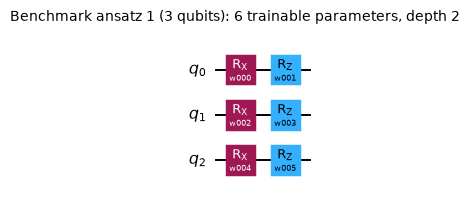

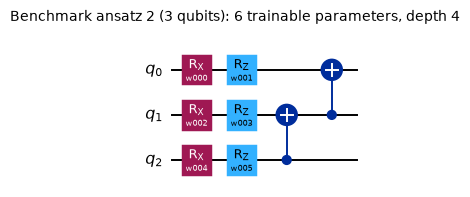

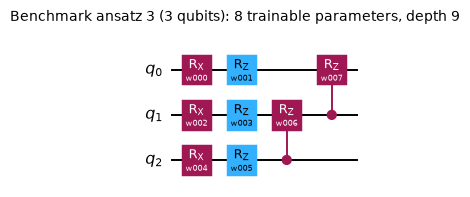

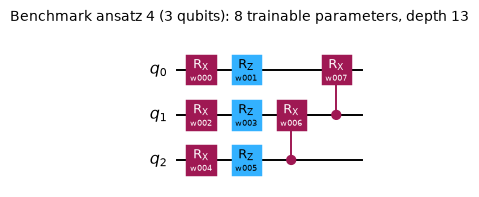

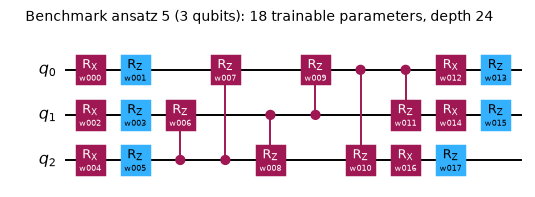

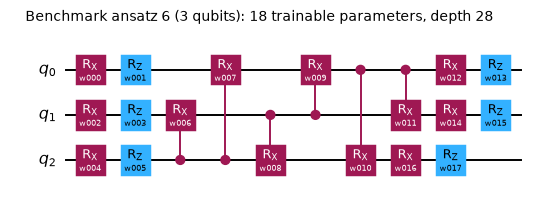

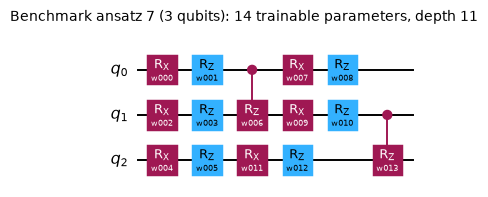

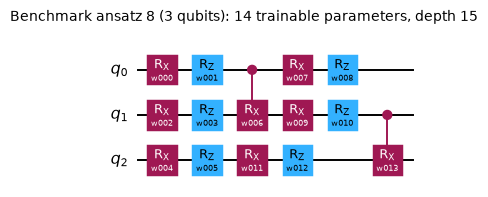

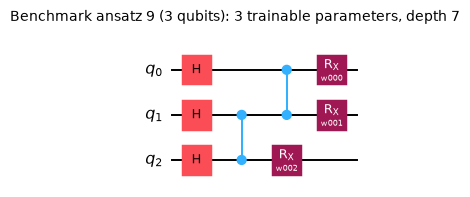

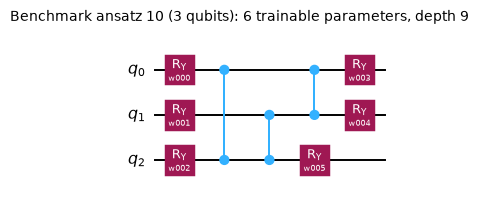

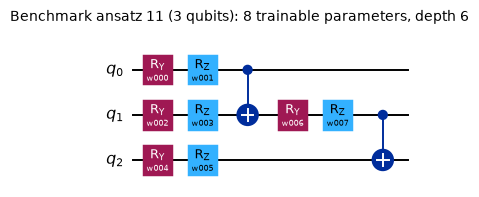

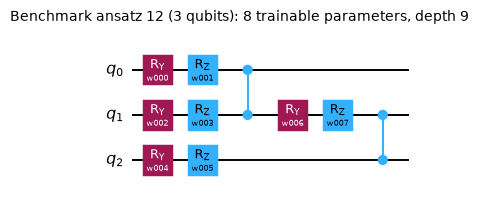

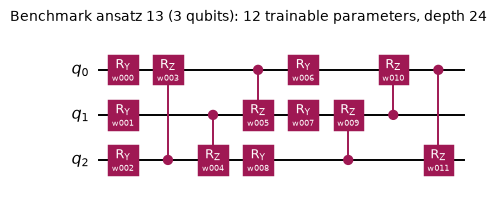

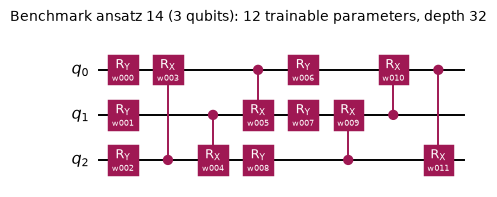

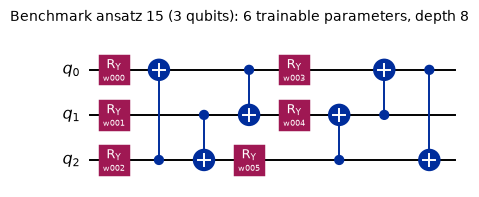

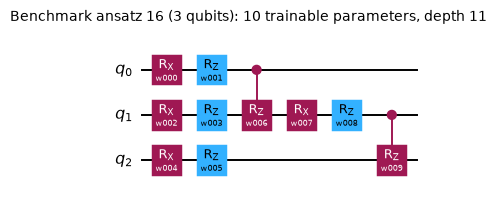

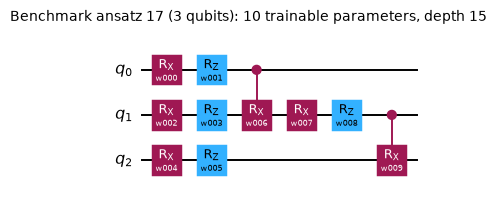

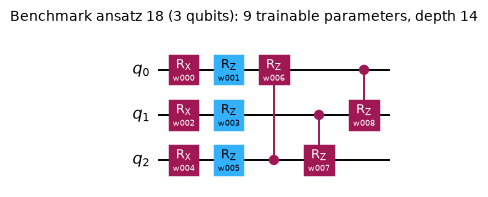

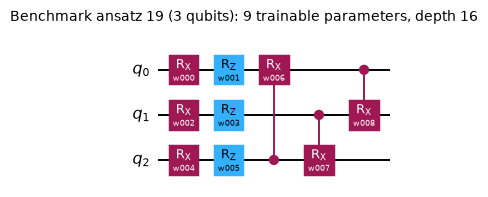

In [15]:
# ---- the 19 benchmark ansatzes used in the Fig. 6 / 7 ablation, drawn for 3 qubits (one drawing per distinct architecture) ----
for k in range(1, 20):
    a = sim_ansatz(k, 3)
    show_circuit(a, f"Benchmark ansatz {k} (3 qubits): {len(a._plist)} trainable parameters, depth {a.decompose().depth()}", fold=-1, scale=0.7)

## 3. Fast, verified simulation of the circuits

Training a 7-qubit VQC with Qiskit's primitives costs about 30 ms per node and evaluation, i.e. many minutes per COBYLA run, and the
ablation needs 100+ fits. The circuits are small enough to simulate exactly in NumPy, so the notebook uses exact routines and
**asserts that they agree with Qiskit's own objects**:

* the **feature-map state** `|phi(x)>`: Qiskit's `Statevector` of the bound circuit for the QRAC encodings (at most 128 distinct
  inputs); vectorised NumPy formulas for the ZZ map (`H^n`, then the diagonal phase `exp(i[sum_i 2 x_i b_i + sum_{i<j} 2 (pi - x_i)(pi - x_j)(b_i xor b_j)])`,
  repeated twice) and for the Z map (a product state); the normalised amplitude vector for amplitude encoding;
* the **ansatz** unitary `U(w)`: `Operator` of the Qiskit circuit with the weights bound; the VQC output is
  `<phi(x)| U^dagger (Z x ... x Z) U |phi(x)>`, compared with the executed bound circuit (and with `EstimatorQNN`) on random nodes
  and weights, for the main ansatz and for all 19 benchmark ansatzes.

In [16]:
HN = {}
def hadamard_n(n):
    if n not in HN:
        H1 = np.array([[1, 1], [1, -1]]) / np.sqrt(2); M = np.array([[1.0]])
        for _ in range(n): M = np.kron(M, H1)
        HN[n] = M
    return HN[n]

def zz_states(A, reps=2):
    """Exact states of zz_feature_map(n, reps, entanglement='full') for all rows of A (vectorised)."""
    A = np.asarray(A, float); N, n = A.shape; dim = 2 ** n
    b = ((np.arange(dim)[:, None] >> np.arange(n)) & 1).astype(float)              # b[:, i] = value of qubit i
    pairs = [(i, j) for i in range(n) for j in range(i + 1, n)]
    xor = np.stack([np.abs(b[:, i] - b[:, j]) for i, j in pairs], axis=1)
    P = np.stack([(np.pi - A[:, i]) * (np.pi - A[:, j]) for i, j in pairs], axis=1)
    phase = 2 * A @ b.T + 2 * P @ xor.T
    ph = np.exp(1j * phase); psi = np.full((N, dim), 1 / np.sqrt(dim), complex) * ph
    for _ in range(reps - 1):
        psi = (psi @ hadamard_n(n)) * ph
    return psi

def z_states(A, reps=2):
    """Exact states of z_feature_map(n, reps) (H, P(2x) repeated): a product state."""
    A = np.asarray(A, float); N, n = A.shape; psi = np.ones((N, 1), complex)
    for i in reversed(range(n)):                                                   # qubit n-1 is the most significant bit
        ph = np.exp(2j * A[:, i]); s = np.stack([np.full(N, 1 / np.sqrt(2), complex), np.full(N, 1 / np.sqrt(2), complex) * ph], 1)
        for _ in range(reps - 1):
            s = np.stack([(s[:, 0] + s[:, 1]), (s[:, 0] - s[:, 1])], 1) / np.sqrt(2) * np.stack([np.ones(N), ph], 1)
        psi = (psi[:, :, None] * s[:, None, :]).reshape(N, -1)
    return psi

def states_unique(e, A):
    """(states of the unique rows of A, index of every row into them)."""
    Au, inv = np.unique(np.round(np.asarray(A, float), 12), axis=0, return_inverse=True)
    nm = e["name"]
    if nm.startswith("ZZ"): S = zz_states(Au, reps=2)
    elif nm == "Z-raw": S = z_states(Au, reps=2)
    elif nm == "AE-raw": S = Au.astype(complex)
    else:
        fmd = e["fm"].decompose(); S = np.array([Statevector(fmd.assign_parameters(a)).data for a in Au])
    return S, inv.ravel()

SPLITS = {"tr": X_tr, "te": X_te}
STATES, TENC = {}, {}
def get_states(e, split):
    k = (e["name"], e["mode"], split)
    if k not in STATES:
        t0 = time.time(); STATES[k] = states_unique(e, e["tf"](SPLITS[split])); TENC[(e["name"], e["mode"])] = TENC.get((e["name"], e["mode"]), 0) + time.time() - t0
    return STATES[k]
for key, e in ENC.items():
    get_states(e, "tr"); get_states(e, "te")
print("states prepared; seconds to prepare the train + test states per encoding:")
print({f"{k[0]}{'' if k[1] == 'train' else ' [paper median]'}": round(v, 2) for k, v in TENC.items()})

# ---- verification against Qiskit ----
for name in ("ZZ-raw", "ZZ-scaled", "Z-raw"):
    e = ENC[(name, "train")]; A = e["tf"](X_tr[::37][:9]); S, inv = states_unique(e, A)
    for k, a in enumerate(A):
        ref = Statevector(e["fm"].assign_parameters(a)).data
        assert abs(abs(np.vdot(ref, S[inv[k]])) - 1) < 1e-9, (name, k)
    print(f"{name}: NumPy states equal Qiskit's Statevector (up to a global phase) on {len(A)} training nodes")
print("AE-raw: amplitudes equal the Statevector of the state-preparation circuit (checked above)")

def vqc_scores(Phi, U, n): return (np.abs(Phi @ U.T) ** 2) @ SIGNS[n]                  # <Z..Z> after the ansatz

def exec_score(e, a, ans, w):
    """<Z..Z> of the circuit that is actually executed for one node (Qiskit Statevector)."""
    return Statevector(bound_vqc_circuit(e, a, ans, w)).expectation_value(SparsePauliOp("Z" * e["n"])).real

# main ansatz vs EstimatorQNN (parametric feature maps) and vs the executed bound circuit (all encodings)
for key, e in ENC.items():
    if key[1] != "train": continue
    ans = main_ansatz(e["n"]); w = np.random.default_rng(5).uniform(0, 2 * np.pi, len(plist(ans)))
    A = e["tf"](X_te[:4]); S, inv = states_unique(e, A)
    fast = vqc_scores(S[inv], unitary(ans, w), e["n"])
    ref = np.array([exec_score(e, a, ans, w) for a in A])
    assert np.allclose(fast, ref, atol=1e-8), (key, fast, ref)
    if key[0] != "AE-raw":
        qc = QuantumCircuit(e["n"]); qc.compose(e["fm"], inplace=True); qc.compose(ans, inplace=True)
        qnn = EstimatorQNN(circuit=qc, input_params=list(e["fm"].parameters), weight_params=plist(ans), observables=SparsePauliOp("Z" * e["n"]),
                           estimator=StatevectorEstimator(), input_gradients=False, default_precision=0.0)
        assert np.allclose(fast, qnn.forward(A, w)[:, 0], atol=1e-8), key
print("fast VQC read-out == executed bound circuit == EstimatorQNN for every encoding with the main ansatz")

# all 19 benchmark ansatzes (Operator-based unitary of the generator vs executed bound circuit)
for k in range(1, 20):
    for name in ("QRAC-3q(3,1)", "QRAC-2q(3,1)", "Z-raw", "AE-raw"):
        e = ENC[(name, "train")]; ans = sim_ansatz(k, e["n"]); w = np.random.default_rng(k).uniform(0, 2 * np.pi, len(plist(ans)))
        A = e["tf"](X_te[:2]); S, inv = states_unique(e, A)
        assert np.allclose(vqc_scores(S[inv], unitary(ans, w), e["n"]), [exec_score(e, a, ans, w) for a in A], atol=1e-8), (k, name)
print("all 19 benchmark ansatzes x {QRAC-3q, QRAC-2q, Z-raw (7 qubits), AE-raw}: fast read-out == executed circuit")

states prepared; seconds to prepare the train + test states per encoding:
{'ZZ-raw': 0.48, 'ZZ-scaled': 0.51, 'Z-raw': 0.24, 'AE-raw': 0.09, 'QRAC-3q(3,1)': 1.18, 'QRAC-2q(3,1)': 0.65, 'QRAC-cat(2,1)': 0.2, 'QRAC-cat(3,1)': 0.23, 'QRAC-3q(3,1) [paper median]': 0.74, 'QRAC-2q(3,1) [paper median]': 0.82}


ZZ-raw: NumPy states equal Qiskit's Statevector (up to a global phase) on 9 training nodes


ZZ-scaled: NumPy states equal Qiskit's Statevector (up to a global phase) on 9 training nodes
Z-raw: NumPy states equal Qiskit's Statevector (up to a global phase) on 9 training nodes
AE-raw: amplitudes equal the Statevector of the state-preparation circuit (checked above)


fast VQC read-out == executed bound circuit == EstimatorQNN for every encoding with the main ansatz


all 19 benchmark ansatzes x {QRAC-3q, QRAC-2q, Z-raw (7 qubits), AE-raw}: fast read-out == executed circuit


## 4. Evaluation helpers and the classical baselines

All metrics treat **phishing as the positive class**. For every model we store the predictions on the test set and compute
(i) metrics on the whole test set (1:10 imbalanced, the setting of the paper's Figs. 5-7) and (ii) metrics averaged over
`N_BAL_DRAWS` random balanced 150 + 150 subsets (the setting of Tables II and III). The classical baselines see the **same inputs** as
the quantum models: the 7 raw features (the paper's classical SVM and LGBM), the 7 median bits and the 3 categorised features
that the QRAC circuits receive.

In [17]:
RES = []          # one row per (model, encoding, seed)
PRED = {}         # predictions on the test set

def metric_row(y, p):
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, labels=[0, 1], zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y, p, labels=[0, 1]).ravel()
    return {"macro_f1": f1.mean(), "phish_f1": f1[1], "phish_prec": pr[1], "phish_rec": rc[1], "FN": fn, "FP": fp, "TP": tp, "TN": tn}

def register(model, enc, seed, pred, t_fit, t_pred, extra=None):
    pred = np.asarray(pred).astype(int)
    full = metric_row(y_te, pred)
    bal = pd.DataFrame([metric_row(y_te[i], pred[i]) for i in BAL_DRAWS]).mean()
    row = {"model": model, "encoding": enc, "seed": seed, "t_fit_s": t_fit, "t_pred_s": t_pred,
           **{f"full_{k}": v for k, v in full.items()}, **{f"bal_{k}": bal[k] for k in ("macro_f1", "phish_f1", "phish_prec", "phish_rec")}}
    if extra: row.update(extra)
    RES.append(row); PRED[(model, enc, seed)] = pred
    return row

COLS = ("full_macro_f1", "full_phish_f1", "full_phish_rec", "full_FN", "full_FP", "bal_macro_f1", "bal_phish_f1", "bal_phish_rec", "t_fit_s")
def show(models=None, cols=COLS):
    df = pd.DataFrame(RES)
    if models is not None: df = df[df["model"].isin(models)]
    g = df.groupby(["model", "encoding"], sort=False)[list(cols)].agg(["mean", "std"]) if df["seed"].nunique() > 1 else df.set_index(["model", "encoding"])[list(cols)]
    return g.round(3)

# ---- classical baselines on identical inputs ----
BASE_MODELS = {"SVC-rbf": lambda: SVC(kernel="rbf"), LGBM_NAME: LGBM, "RandomForest": lambda: RandomForestClassifier(n_estimators=100, random_state=SEED)}
INPUTS = {"raw-7": (X_tr, X_te), "bits-7": ((X_tr > THR_TRAIN).astype(float), (X_te > THR_TRAIN).astype(float)),
          "cat-3": (cat_codes(X_tr).astype(float), cat_codes(X_te).astype(float))}
for model_name, mk in BASE_MODELS.items():
    for inp, (A, B) in INPUTS.items():
        m = mk(); t0 = time.time(); m.fit(A, y_tr); t1 = time.time(); p = m.predict(B); t2 = time.time()
        register(model_name, inp, 0, p, t1 - t0, t2 - t1)
show()

full_macro_f1  full_phish_f1  full_phish_rec  full_FN  \
model        encoding                                                          
SVC-rbf      raw-7             0.728          0.500           0.441      559   
             bits-7            0.836          0.711           0.941       59   
             cat-3             0.655          0.448           0.979       21   
LGBM         raw-7             0.821          0.687           0.968       32   
             bits-7            0.847          0.730           0.939       61   
             cat-3             0.781          0.620           0.891      109   
RandomForest raw-7             0.793          0.642           0.969       31   
             bits-7            0.845          0.726           0.941       59   
             cat-3             0.781          0.618           0.877      123   

                       full_FP  bal_macro_f1  bal_phish_f1  bal_phish_rec  \
model        encoding                                                       
SVC-rbf      raw-7         324         0.686         0.604          0.448   
             bits-7        706         0.937         0.937          0.943   
             cat-3        2395         0.866         0.881          0.978   
LGBM         raw-7         849         0.945         0.946          0.968   
             bits-7        632         0.939         0.939          0.941   
             cat-3         985         0.894         0.894          0.888   
RandomForest raw-7        1048         0.936         0.938          0.971   
             bits-7        652         0.938         0.939          0.943   
             cat-3         959         0.888         0.887          0.875   

                       t_fit_s  
model        encoding           
SVC-rbf      raw-7       0.010  
             bits-7      0.015  
             cat-3       0.004  
LGBM         raw-7       0.080  
             bits-7      0.045  
             cat-3       0.035  
RandomForest raw-7       0.656  
             bits-7      0.692  
             cat-3       0.679

## 5. QSVM with a quantum kernel (QSVM-qiskit)

The kernel of two nodes is the fidelity of their encoded states, `K(a, b) = |<phi(a)|phi(b)>|^2` (Eq. 4-6). We form the kernel
matrix with one matrix product of the exact states and train `SVC(kernel="precomputed", C=1)` on the 320 x 320 training kernel. The
paper's `QSVC` does the same with its default `C = 1`; the second cell proves it by comparing with Qiskit's own
`QSVC(quantum_kernel=FidelityStatevectorKernel(...))`. Encodings: ZZ (the baseline), the two binarised QRACs (Table III) and, as an
extra, the paper-literal median and the categorised QRACs.

In [18]:
def kernel_block(Sa, ia, Sb, ib):
    return (np.abs(Sa @ Sb.conj().T) ** 2)[np.ix_(ia, ib)]

def enc_label(name, mode):
    return name if mode == "train" else f"{name} [paper median]"

QSVM_STORE = {}
QSVM_KEYS = [k for k in ENC if k[0] in ("ZZ-raw", "ZZ-scaled", "QRAC-3q(3,1)", "QRAC-2q(3,1)", "QRAC-cat(2,1)", "QRAC-cat(3,1)")]
def run_qsvm(key, C=1.0):
    e = ENC[key]; t0 = time.time()
    S_tr, i_tr = get_states(e, "tr"); S_te, i_te = get_states(e, "te")
    K_tr = kernel_block(S_tr, i_tr, S_tr, i_tr); K_te = kernel_block(S_te, i_te, S_tr, i_tr)
    svc = SVC(kernel="precomputed", C=C).fit(K_tr, y_tr); t1 = time.time()
    p = svc.predict(K_te); t2 = time.time()
    QSVM_STORE[key] = {"svc": svc, "K_tr": K_tr, "K_te": K_te, "pred": p}
    register("QSVM", enc_label(*key), 0, p, t1 - t0 + TENC[(key[0], key[1])], t2 - t1, {"n_support": len(svc.support_)})

for key in QSVM_KEYS: run_qsvm(key)
print("QSVM done for", len(QSVM_KEYS), "encodings")
show(["QSVM"], cols=("full_macro_f1", "full_phish_f1", "full_phish_rec", "full_FN", "full_FP", "bal_macro_f1", "bal_phish_f1", "bal_phish_rec", "n_support", "t_fit_s"))

QSVM done for 8 encodings


full_macro_f1  full_phish_f1  \
model encoding                                                    
QSVM  ZZ-raw                               0.657          0.450   
      ZZ-scaled                            0.653          0.444   
      QRAC-3q(3,1)                         0.857          0.746   
      QRAC-2q(3,1)                         0.821          0.686   
      QRAC-cat(2,1)                        0.654          0.446   
      QRAC-cat(3,1)                        0.774          0.608   
      QRAC-3q(3,1) [paper median]          0.800          0.655   
      QRAC-2q(3,1) [paper median]          0.733          0.552   

                                   full_phish_rec  full_FN  full_FP  \
model encoding                                                        
QSVM  ZZ-raw                                0.981       19     2377   
      ZZ-scaled                             0.977       23     2419   
      QRAC-3q(3,1)                          0.942       58      583   
      QRAC-2q(3,1)                          0.933       67      787   
      QRAC-cat(2,1)                         0.979       21     2416   
      QRAC-cat(3,1)                         0.892      108     1043   
      QRAC-3q(3,1) [paper median]           0.978       22     1009   
      QRAC-2q(3,1) [paper median]           0.980       20     1568   

                                   bal_macro_f1  bal_phish_f1  bal_phish_rec  \
model encoding                                                                 
QSVM  ZZ-raw                              0.872         0.886          0.981   
      ZZ-scaled                           0.870         0.884          0.976   
      QRAC-3q(3,1)                        0.942         0.942          0.944   
      QRAC-2q(3,1)                        0.928         0.928          0.934   
      QRAC-cat(2,1)                       0.864         0.880          0.978   
      QRAC-cat(3,1)                       0.891         0.891          0.889   
      QRAC-3q(3,1) [paper median]         0.940         0.942          0.977   
      QRAC-2q(3,1) [paper median]         0.914         0.920          0.979   

                                   n_support  t_fit_s  
model encoding                                         
QSVM  ZZ-raw                           238.0    0.791  
      ZZ-scaled                        228.0    0.814  
      QRAC-3q(3,1)                      80.0    1.284  
      QRAC-2q(3,1)                      87.0    0.849  
      QRAC-cat(2,1)                     90.0    0.290  
      QRAC-cat(3,1)                     93.0    0.407  
      QRAC-3q(3,1) [paper median]       52.0    0.924  
      QRAC-2q(3,1) [paper median]       55.0    0.921

QRAC-3q: hand-made kernel == FidelityStatevectorKernel (80 x 80); QSVC predictions == SVC(precomputed) on 400 test nodes


ZZ-scaled: 30 x 30 kernel matches too.  Support vectors (QRAC-3q): 80 of 320


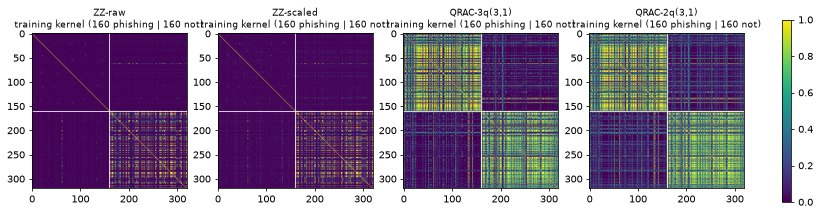

In [19]:
# ---- equivalence with Qiskit's own QSVC + FidelityStatevectorKernel ----
key = ("QRAC-3q(3,1)", "train"); e = ENC[key]; st_ = QSVM_STORE[key]
A_tr_ = e["tf"](X_tr); A_te_ = e["tf"](X_te[:400])
K_ref = FidelityStatevectorKernel(feature_map=e["fm"]).evaluate(A_tr_[:80])
assert np.allclose(K_ref, st_["K_tr"][:80, :80], atol=1e-9), "hand-made kernel differs from FidelityStatevectorKernel"
qsvc = QSVC(quantum_kernel=FidelityStatevectorKernel(feature_map=e["fm"])).fit(A_tr_, y_tr)
assert (qsvc.predict(A_te_) == st_["pred"][:400]).all(), "QSVC predictions differ"
print("QRAC-3q: hand-made kernel == FidelityStatevectorKernel (80 x 80); QSVC predictions == SVC(precomputed) on 400 test nodes")
ez = ENC[("ZZ-scaled", "train")]; Az = ez["tf"](X_tr[:30]); Sz, iz = states_unique(ez, Az)
assert np.allclose(kernel_block(Sz, iz, Sz, iz), FidelityStatevectorKernel(feature_map=ez["fm"]).evaluate(Az), atol=1e-9)
print("ZZ-scaled: 30 x 30 kernel matches too.  Support vectors (QRAC-3q):", len(st_["svc"].support_), "of 320")

fig, ax = plt.subplots(1, 4, figsize=(14, 3.4), dpi=70)
for a, key in zip(ax, [("ZZ-raw", "train"), ("ZZ-scaled", "train"), ("QRAC-3q(3,1)", "train"), ("QRAC-2q(3,1)", "train")]):
    im = a.imshow(QSVM_STORE[key]["K_tr"], vmin=0, vmax=1, cmap="viridis"); a.set_title(key[0] + "\ntraining kernel (160 phishing | 160 not)", fontsize=9)
    a.axhline(159.5, c="w", lw=0.8); a.axvline(159.5, c="w", lw=0.8); a.grid(False)
plt.colorbar(im, ax=ax, fraction=0.012); plt.show()

## 6. Variational Quantum Classifier (VQC)

The circuit is `feature map -> ansatz` and the prediction is the sign of `<Z x ... x Z>`: even parity of the measured bit string
means phishing (+1), odd parity not phishing (-1). Training minimises the mean squared error between that expectation and the +-1 label
with **COBYLA** (`maxiter = VQC_MAXITER`) on an exact statevector simulator (the paper trains on IBM's noiseless statevector
simulator), starting from random weights drawn with the run's seed. Identical (input, label) pairs are merged with a weight, which
gives exactly the same loss as looping over all 320 nodes but is cheaper for QRAC, whose inputs take at most 128 values. This is the
configuration of **Table II** (main ansatz `n_local(ry, rz; cz; reps=2)`).

In [20]:
VQC_STORE = {}
def fit_vqc(e, ans, seed, maxiter, Xs_state=None, ys_=None):
    S, inv = get_states(e, "tr") if Xs_state is None else Xs_state
    ys_ = y_tr if ys_ is None else ys_
    pairs, cnt = np.unique(np.c_[inv, ys_], axis=0, return_counts=True)
    Phi, yu, wu = S[pairs[:, 0]], 2.0 * pairs[:, 1] - 1, cnt / cnt.sum()
    hist = []
    def loss(w):
        out = vqc_scores(Phi, unitary(ans, w), e["n"]); l = float(np.sum(wu * (out - yu) ** 2)); hist.append(l); return l
    w0 = np.random.default_rng(seed).uniform(0, 2 * np.pi, len(plist(ans)))
    res = COBYLA(maxiter=maxiter).minimize(loss, w0)
    return {"ans": ans, "w": np.asarray(res.x), "hist": hist}

def predict_vqc(v, e, split="te"):
    S, inv = get_states(e, split)
    s = vqc_scores(S, unitary(v["ans"], v["w"]), e["n"])[inv]
    return (s > 0).astype(int), s

for key, e in ENC.items():
    if key[0] in ("Z-raw", "AE-raw"): continue                      # Z and AE enter the ablation only
    ans = main_ansatz(e["n"])
    for seed in range(N_SEEDS):
        t0 = time.time(); v = fit_vqc(e, ans, SEED + seed, VQC_MAXITER); t1 = time.time()
        p, s = predict_vqc(v, e); t2 = time.time()
        VQC_STORE[(key, seed)] = v
        register("VQC", enc_label(*key), seed, p, t1 - t0 + TENC[(key[0], key[1])], t2 - t1, {"final_loss": v["hist"][-1]})
        print(f"VQC {enc_label(*key):28s} seed {seed}: train {t1 - t0:6.1f}s  predict {t2 - t1:5.1f}s  loss {v['hist'][0]:.3f} -> {v['hist'][-1]:.3f}  macro-F1(full test) {RES[-1]['full_macro_f1']:.3f}")
show(["VQC"], cols=("full_macro_f1", "full_phish_f1", "full_phish_rec", "full_FN", "full_FP", "bal_macro_f1", "bal_phish_f1", "bal_phish_rec", "final_loss", "t_fit_s"))

VQC ZZ-raw                       seed 0: train   22.9s  predict   0.4s  loss 0.987 -> 0.878  macro-F1(full test) 0.497


VQC ZZ-raw                       seed 1: train   24.6s  predict   0.2s  loss 1.019 -> 0.832  macro-F1(full test) 0.564


VQC ZZ-raw                       seed 2: train   14.6s  predict   0.5s  loss 1.022 -> 0.836  macro-F1(full test) 0.520


VQC ZZ-scaled                    seed 0: train   17.5s  predict   0.3s  loss 0.970 -> 0.904  macro-F1(full test) 0.491


VQC ZZ-scaled                    seed 1: train   16.6s  predict   0.2s  loss 1.044 -> 0.863  macro-F1(full test) 0.541


...

VQC QRAC-3q(3,1) [paper median]  seed 2: train    1.5s  predict   0.0s  loss 0.766 -> 0.290  macro-F1(full test) 0.746


VQC QRAC-2q(3,1) [paper median]  seed 0: train    1.1s  predict   0.0s  loss 1.444 -> 0.250  macro-F1(full test) 0.749


VQC QRAC-2q(3,1) [paper median]  seed 1: train    1.0s  predict   0.0s  loss 2.129 -> 0.251  macro-F1(full test) 0.739


VQC QRAC-2q(3,1) [paper median]  seed 2: train    1.0s  predict   0.0s  loss 2.019 -> 0.273  macro-F1(full test) 0.697


full_macro_f1        full_phish_f1         \
                                           mean    std          mean    std   
model encoding                                                                
VQC   ZZ-raw                              0.527  0.034         0.241  0.033   
      ZZ-scaled                           0.514  0.025         0.220  0.025   
      QRAC-3q(3,1)                        0.759  0.004         0.585  0.006   
      QRAC-2q(3,1)                        0.822  0.014         0.684  0.023   
      QRAC-cat(2,1)                       0.778  0.003         0.600  0.005   
      QRAC-cat(3,1)                       0.738  0.069         0.557  0.093   
      QRAC-3q(3,1) [paper median]         0.734  0.032         0.554  0.046   
      QRAC-2q(3,1) [paper median]         0.728  0.027         0.546  0.039   

                                  full_phish_rec         full_FN          \
                                            mean    std     mean     std   
model encoding                                                             
VQC   ZZ-raw                               0.515  0.008  485.333   8.083   
      ZZ-scaled                            0.475  0.023  525.333  23.180   
      QRAC-3q(3,1)                         0.903  0.027   97.333  27.025   
      QRAC-2q(3,1)                         0.844  0.003  156.000   3.464   
      QRAC-cat(2,1)                        0.672  0.006  328.333   5.508   
      QRAC-cat(3,1)                        0.880  0.093  119.667  93.458   
      QRAC-3q(3,1) [paper median]          0.975  0.005   25.000   4.583   
      QRAC-2q(3,1) [paper median]          0.979  0.001   20.667   0.577   

                                    full_FP          bal_macro_f1         \
                                       mean      std         mean    std   
model encoding                                                             
VQC   ZZ-raw                       2808.333  515.039        0.611  0.028   
      ZZ-scaled                    2859.667  387.450        0.588  0.025   
      QRAC-3q(3,1)                 1182.000   58.924        0.893  0.009   
      QRAC-2q(3,1)                  624.667   86.933        0.894  0.001   
      QRAC-cat(2,1)                 566.000   12.288        0.796  0.002   
      QRAC-cat(3,1)                1380.333  831.733        0.868  0.025   
      QRAC-3q(3,1) [paper median]  1565.000  311.283        0.910  0.013   
      QRAC-2q(3,1) [paper median]  1620.333  267.948        0.909  0.012   

                                  bal_phish_f1        bal_phish_rec         \
                                          mean    std          mean    std   
model encoding                                                               
VQC   ZZ-raw                             0.571  0.022         0.512  0.008   
      ZZ-scaled                          0.541  0.027         0.478  0.029   
      QRAC-3q(3,1)                       0.895  0.011         0.906  0.024   
      QRAC-2q(3,1)                       0.889  0.001         0.851  0.005   
      QRAC-cat(2,1)                      0.766  0.003         0.656  0.004   
      QRAC-cat(3,1)                      0.868  0.031         0.876  0.098   
      QRAC-3q(3,1) [paper median]        0.916  0.011         0.973  0.005   
      QRAC-2q(3,1) [paper median]        0.915  0.010         0.978  0.001   

                                  final_loss        t_fit_s         
                                        mean    std    mean    std  
model encoding                                                      
VQC   ZZ-raw                           0.849  0.026  21.195  5.329  
      ZZ-scaled                        0.870  0.032  19.579  3.564  
      QRAC-3q(3,1)                     0.323  0.015   4.919  1.946  
      QRAC-2q(3,1)                     0.330  0.001   2.221  0.564  
      QRAC-cat(2,1)                    0.483  0.013   1.943  0.594  
      QRAC-cat(3,1)                    0.412  0.023   1.571  0.122  
      QRAC

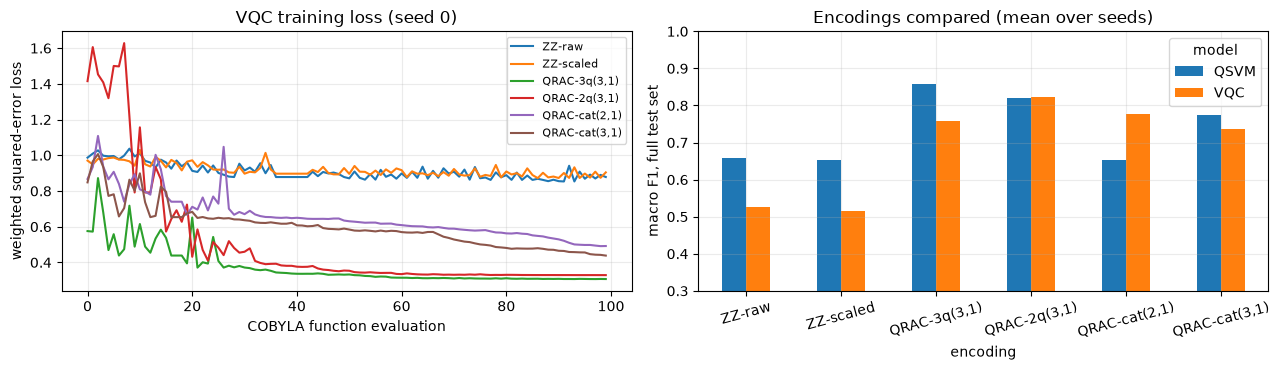

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for key in ENC:
    if key[1] != "train" or (key, 0) not in VQC_STORE: continue
    ax[0].plot(VQC_STORE[(key, 0)]["hist"], label=key[0])
ax[0].set_xlabel("COBYLA function evaluation"); ax[0].set_ylabel("weighted squared-error loss"); ax[0].set_title("VQC training loss (seed 0)"); ax[0].legend(fontsize=8)
d = pd.DataFrame(RES); d = d[d["model"].isin(["QSVM", "VQC"]) & ~d["encoding"].str.contains("paper median")]
order = [n for n in ENCODINGS if n not in ("Z-raw", "AE-raw")]
piv = d.groupby(["encoding", "model"], sort=False)["full_macro_f1"].mean().unstack().reindex(order)
piv.plot.bar(ax=ax[1], rot=15); ax[1].set_ylabel("macro F1, full test set"); ax[1].set_title("Encodings compared (mean over seeds)"); ax[1].set_ylim(0.3, 1)
plt.tight_layout(); plt.show()

## 7. QSVM by annealing (QSVM-dwave)

The SVM dual with a kernel `K` is `min_lambda 1/2 lambda^T (K . y y^T) lambda - 1^T lambda`, `lambda >= 0`. Each
multiplier is written with binary variables, `lambda_i = sum_k p_k b_ik` with the precision vector `p = [1, 2]`
(so `lambda_i` in {0,1,2,3}), which gives a QUBO with 2 x 320 = 640 binary variables. The paper sends it to a D-Wave machine (Table III
lists identical scores for "classical annealing" and the D-Wave 5617-qubit device); **no annealer is available here**, so the identical
QUBO is solved with `dwave.samplers.SimulatedAnnealingSampler` and an RBF kernel with `sigma = 150` (the value of the authors' follow-up
work; the 2023 paper does not give it). Prediction: `sign(sum_i lambda_i y_i K(x, x_i) + b)` with
`b = mean_i(y_i - sum_j lambda_j y_j K_ji)`. This is a QUBO / annealing method, **not a gate circuit**, so the circuit section does not draw it.

In [22]:
from sklearn.metrics.pairwise import rbf_kernel

def qsvm_qubo(K, y, precision=QA_PRECISION):
    ys = 2.0 * y - 1; N = len(y); p = np.asarray(precision, float); nb = len(p)
    P = np.kron(np.eye(N), p[None, :])                       # lambda = P @ b, shape (N, N*nb)
    Qm = K * np.outer(ys, ys)
    H = P.T @ Qm @ P; h = -P.T @ np.ones(N)                  # E(b) = 1/2 b^T H b + h^T b, b binary
    nv = N * nb
    lin = {i: float(0.5 * H[i, i] + h[i]) for i in range(nv)}
    iu, ju = np.triu_indices(nv, 1)
    quad = {(int(i), int(j)): float(H[i, j]) for i, j in zip(iu, ju)}
    return dimod.BinaryQuadraticModel(lin, quad, 0.0, "BINARY"), P, H, h

gamma = 1.0 / (2.0 * SIGMA ** 2)                             # K = exp(-||x - x'||^2 / (2 sigma^2))
Kq_tr = rbf_kernel(X_tr, X_tr, gamma=gamma); Kq_te = rbf_kernel(X_te, X_tr, gamma=gamma)
print(f"RBF kernel sigma={SIGMA:g}: training kernel entries in [{Kq_tr.min():.3f}, {Kq_tr.max():.3f}]")
t0 = time.time(); bqm, P, H, hvec = qsvm_qubo(Kq_tr, y_tr)
ss = SimulatedAnnealingSampler().sample(bqm, num_reads=QA_READS, num_sweeps=QA_SWEEPS, seed=SEED)
best = ss.first; bvec = np.array([best.sample[i] for i in range(len(bqm.variables))], float)
assert abs(best.energy - (0.5 * bvec @ H @ bvec + hvec @ bvec)) < 1e-6          # the BQM is the intended QUBO
lam = P @ bvec; ys = 2.0 * y_tr - 1
b_off = float(np.mean(ys - (lam * ys) @ Kq_tr))
t1 = time.time()
dec = (Kq_te @ (lam * ys)) + b_off; p_qa = (dec > 0).astype(int); t2 = time.time()
register("QSVM-anneal (SA)", f"RBF sigma={SIGMA:g}", 0, p_qa, t1 - t0, t2 - t1, {"qubo_energy": float(best.energy), "n_sv": int((lam > 0).sum())})
print(f"QUBO: {len(bqm.variables)} binary variables, {bqm.num_interactions} couplings | best energy {best.energy:.2f} over {QA_READS} reads "
      f"(worst {ss.record.energy.max():.2f}) | support vectors {(lam > 0).sum()} | multipliers {np.bincount(lam.astype(int))} | {t1 - t0:.1f}s")
t0 = time.time(); svm_ref = SVC(kernel="precomputed", C=float(sum(QA_PRECISION))).fit(Kq_tr, y_tr); t1 = time.time()
register("SVC (precomputed RBF sigma=150)", f"RBF sigma={SIGMA:g}", 0, svm_ref.predict(Kq_te), t1 - t0, 0.0)
show(["QSVM-anneal (SA)", "SVC (precomputed RBF sigma=150)"])

RBF kernel sigma=150: training kernel entries in [0.000, 1.000]


QUBO: 640 binary variables, 204480 couplings | best energy -424.05 over 50 reads (worst -398.35) | support vectors 204 | multipliers [116  51  22 131] | 4.7s


,,full_macro_f1,full_phish_f1,full_phish_rec,full_FN,full_FP,bal_macro_f1,bal_phish_f1,bal_phish_rec,t_fit_s
model,encoding,,,,,,,,,
QSVM-anneal (SA),RBF sigma=150,0.758,0.561,0.568,432,457,0.762,0.719,0.591,4.721
SVC (precomputed RBF sigma=150),RBF sigma=150,0.761,0.570,0.626,374,569,0.787,0.755,0.646,0.008


## 8. Encoding ablation over the benchmark ansatzes (Figures 6 and 7)

The paper trains the VQC with 19 ansatzes of different entangling capacity and compares encodings for each of them: **Fig. 6** (categorised
data for the two QRACs; real-valued features for Z, ZZ and amplitude encoding) and **Fig. 7** (binarised data for the 2-qubit and 3-qubit
(3,1)-QRAC; real features for Z, ZZ, AE). The bars carry no printed values, so we compute the same grid (training set 160 + 160, full test set,
one seed, `ABL_MAXITER` COBYLA iterations; `FAST_MODE` runs only the ansatzes in `ABL_ANSATZ`) and later check the paper's *statements* about
it. The y-axis of the figures is the F-score; we report macro F1 on the whole test set (the metric of Fig. 5).

In [23]:
ABL_REAL = ["Z-raw", "ZZ-raw", "AE-raw"]; ABL_CAT = ["QRAC-cat(2,1)", "QRAC-cat(3,1)"]; ABL_BIN = ["QRAC-2q(3,1)", "QRAC-3q(3,1)"]
ABL = []
t_all = time.time()
for k in ABL_ANSATZ:
    t0 = time.time()
    for name in ABL_REAL + ABL_CAT + ABL_BIN:
        e = ENC[(name, "train")]; ans = sim_ansatz(k, e["n"])
        v = fit_vqc(e, ans, SEED, ABL_MAXITER); p, _ = predict_vqc(v, e)
        m = metric_row(y_te, p)
        ABL.append({"ansatz": k, "encoding": name, "params": len(plist(ans)), "macro_f1": m["macro_f1"], "phish_f1": m["phish_f1"], "phish_rec": m["phish_rec"], "FN": m["FN"], "FP": m["FP"]})
    print(f"ansatz {k:2d} done in {time.time() - t0:5.1f}s  (total {time.time() - t_all:6.1f}s)", flush=True)
ABLD = pd.DataFrame(ABL)
M = ABLD.pivot(index="ansatz", columns="encoding", values="macro_f1")
display(M[ABL_REAL + ABL_CAT + ABL_BIN].round(3))

ansatz  1 done in   8.6s  (total    8.6s)


ansatz  2 done in  13.9s  (total   22.5s)


ansatz  3 done in  16.0s  (total   38.5s)


ansatz  4 done in  19.8s  (total   58.3s)


ansatz  5 done in  39.0s  (total   97.3s)


...

ansatz 16 done in  29.0s  (total  388.9s)


ansatz 17 done in  28.0s  (total  416.9s)


ansatz 18 done in  28.7s  (total  445.6s)


ansatz 19 done in  24.1s  (total  469.7s)


encoding,Z-raw,ZZ-raw,AE-raw,"QRAC-cat(2,1)","QRAC-cat(3,1)","QRAC-2q(3,1)","QRAC-3q(3,1)"
ansatz,,,,,,,
1,0.669,0.508,0.562,0.689,0.496,0.633,0.644
2,0.425,0.541,0.562,0.591,0.621,0.772,0.760
3,0.567,0.508,0.562,0.689,0.496,0.633,0.644
4,0.626,0.531,0.570,0.624,0.636,0.758,0.760
5,0.630,0.511,0.547,0.653,0.770,0.813,0.812
6,0.717,0.521,0.548,0.653,0.658,0.786,0.830
7,0.631,0.565,0.547,0.593,0.604,0.814,0.645
8,0.598,0.555,0.556,0.614,0.632,0.689,0.767
9,0.576,0.508,0.590,0.590,0.721,0.744,0.684


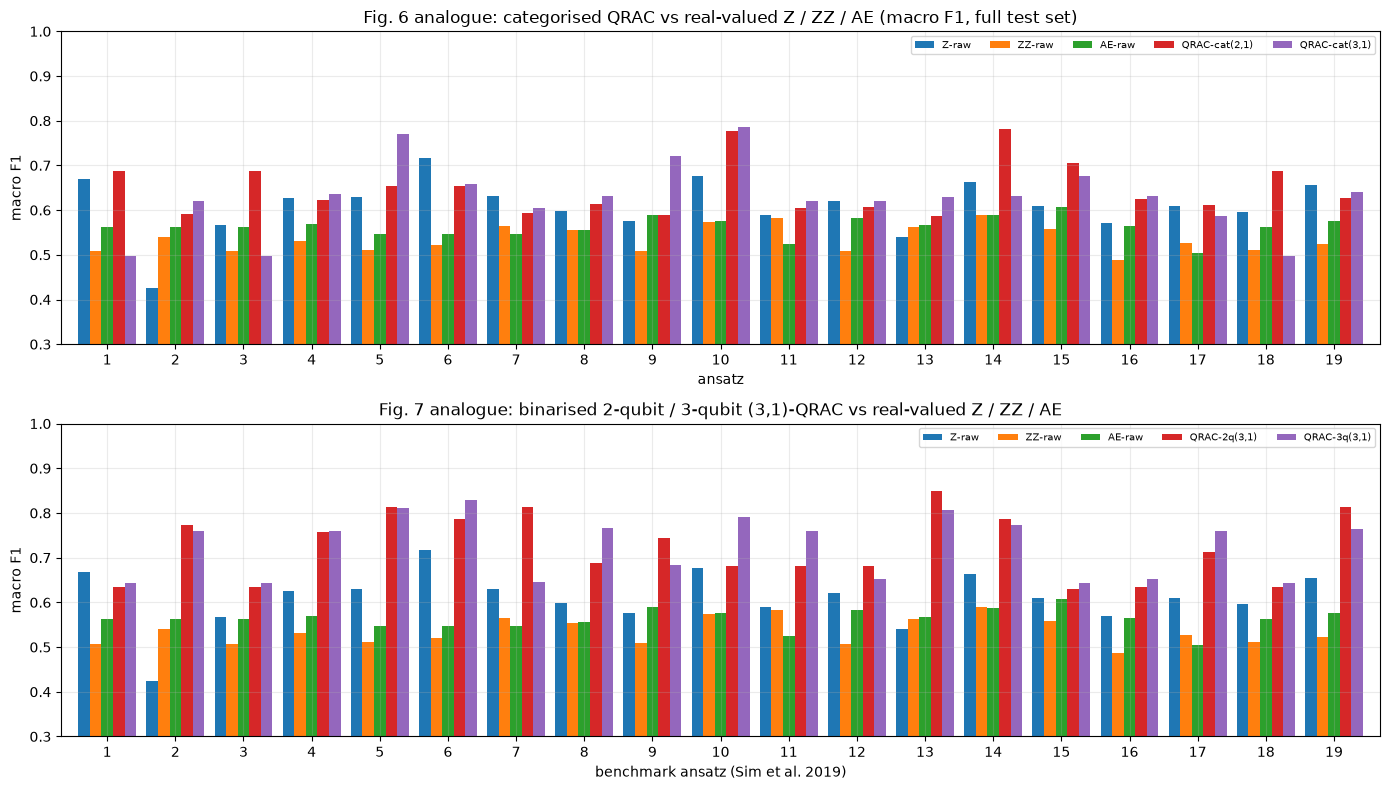

In [24]:
fig, ax = plt.subplots(2, 1, figsize=(14, 8), sharey=True)
M[ABL_REAL + ABL_CAT].plot.bar(ax=ax[0], width=0.85, rot=0); ax[0].set_title("Fig. 6 analogue: categorised QRAC vs real-valued Z / ZZ / AE (macro F1, full test set)")
M[ABL_REAL + ABL_BIN].plot.bar(ax=ax[1], width=0.85, rot=0); ax[1].set_title("Fig. 7 analogue: binarised 2-qubit / 3-qubit (3,1)-QRAC vs real-valued Z / ZZ / AE")
for a in ax: a.set_ylabel("macro F1"); a.set_ylim(0.3, 1); a.legend(fontsize=7, ncol=5)
ax[1].set_xlabel("benchmark ansatz (Sim et al. 2019)"); plt.tight_layout(); plt.show()

## 9. A noisy-simulator stand-in for the IBM hardware rows

The paper ran the trained circuits on IBM devices (ibmq_belem, ibmq_geneva, ibm_montreal, ibm_perth, ibm_washington), without error mitigation, on 300
test nodes. A real device is not part of this notebook, but `qiskit_ibm_runtime.fake_provider` ships snapshots of the calibration data of these
machines; `AerSimulator.from_backend` turns each into a noisy simulator (gate errors, T1/T2 relaxation, readout errors, native gates, coupling
map). We run the **same trained models** through it with `HW_SHOTS` shots, circuits transpiled with `optimization_level=1`:

* **VQC**: each test node's circuit (feature map + trained ansatz + measurements) is run; the label is the sign of the parity expectation
  estimated from the counts. Nodes with identical angle vectors share one executed circuit.
* **QSVM**: the kernel entries between the test nodes and the *support vectors only* are estimated as the frequency of the all-zeros outcome of the
  compute-uncompute circuit, exactly the saving described in Sec. II-C of the paper; the SVM decision function is then evaluated classically.

This is a **stand-in**: the calibration snapshot is not the calibration of the day the paper ran, crosstalk and queueing are not modelled, the node
subset differs, and ibmq_belem (5 qubits) cannot hold the 7-qubit ZZ circuit. The ZZ-QSVM on washington would need about 300 x 230 distinct
kernel circuits of 7 qubits and is not run. Real-device numbers therefore remain "cannot be checked".

In [25]:
import qiskit_ibm_runtime.fake_provider as fp
from qiskit_aer import AerSimulator

h = HW_N_TEST // 2
HW_IDX = np.r_[BAL_DRAWS[0][:150][:h], BAL_DRAWS[0][150:][:h]]            # balanced subset of the test set
yhw, Xhw = y_te[HW_IDX], X_te[HW_IDX]

def fake(name):
    try: return getattr(fp, name)()
    except Exception as ex:
        print("fake backend", name, "unavailable:", ex); return None

def run_counts(circs, backend, sim):
    tc = transpile(circs, backend, optimization_level=1, seed_transpiler=SEED)
    res = sim.run(tc, shots=HW_SHOTS, seed_simulator=SEED).result()
    return [res.get_counts(i) for i in range(len(circs))], tc

def hw_vqc(key, backend, sim, seed=0):
    e = ENC[key]; v = VQC_STORE[(key, seed)]; ans = v["ans"]
    A = e["tf"](Xhw); Au, inv = np.unique(np.round(A, 12), axis=0, return_inverse=True); inv = inv.ravel()
    circs = []
    for a in Au:
        c = bound_vqc_circuit(e, a, ans, v["w"]); c.measure_all(); circs.append(c)
    cnts, tc = run_counts(circs, backend, sim)
    par = np.array([sum(n * (1 if bin(int(b, 2)).count("1") % 2 == 0 else -1) for b, n in c.items()) / HW_SHOTS for c in cnts])
    return (par[inv] > 0).astype(int), PRED[("VQC", enc_label(*key), seed)][HW_IDX], tc[0]

def hw_qsvm(key, backend, sim):
    e = ENC[key]; st_ = QSVM_STORE[key]; svc = st_["svc"]; sv = svc.support_
    A_sv = np.round(e["tf"](X_tr)[sv], 12); A_t = np.round(e["tf"](Xhw), 12)
    Au_t, inv_t = np.unique(A_t, axis=0, return_inverse=True); Au_s, inv_s = np.unique(A_sv, axis=0, return_inverse=True)
    circs = []
    for a in Au_t:
        for b in Au_s:
            c = e["fm"].assign_parameters(a).compose(e["fm"].assign_parameters(b).inverse()); c.measure_all(); circs.append(c)
    cnts, tc = run_counts(circs, backend, sim)
    Ku = np.array([c.get("0" * e["n"], 0) / HW_SHOTS for c in cnts]).reshape(len(Au_t), len(Au_s))
    Kfull = np.zeros((len(Xhw), len(st_["K_tr"]))); Kfull[:, sv] = Ku[np.ix_(inv_t.ravel(), inv_s.ravel())]
    return svc.predict(Kfull), svc.predict(st_["K_te"][HW_IDX]), tc[0]

# (model, encoding, paper device, fake backend class, paper simulator row, paper hardware row)  rows: (macro F1, phishing F1, phishing recall)
HW_PLAN = [("VQC", "ZZ-raw", "ibmq_geneva", "FakeGeneva", (0.67, 0.63, 0.55), (0.64, 0.57, 0.58)),
           ("VQC", "QRAC-3q(3,1)", "ibm_montreal", "FakeMontrealV2", (0.72, 0.53, 0.98), (0.55, 0.33, 0.98)),
           ("VQC", "QRAC-3q(3,1)", "ibm_perth", "FakePerth", (0.72, 0.53, 0.98), (0.53, 0.32, 0.98)),
           ("VQC", "QRAC-2q(3,1)", "ibm_montreal", "FakeMontrealV2", (0.76, 0.59, 0.93), (0.62, 0.41, 0.98)),
           ("QSVM", "QRAC-3q(3,1)", "ibm_washington", "FakeWashingtonV2", (0.93, 0.94, 0.96), (0.93, 0.94, 0.96))]
HW_RESULTS = []; HW_CIRC = {}
for model, enc, dev, cls, p_sim, p_hw in HW_PLAN:
    backend = fake(cls)
    if backend is None: continue
    sim = AerSimulator.from_backend(backend); key = (enc, "train"); t0 = time.time()
    noisy, ideal, tcirc = hw_vqc(key, backend, sim) if model == "VQC" else hw_qsvm(key, backend, sim)
    HW_CIRC[(model, enc, dev)] = tcirc
    mi, mn = metric_row(yhw, ideal), metric_row(yhw, noisy)
    HW_RESULTS.append({"model": model, "encoding": enc, "device (paper)": dev, "stand-in": backend.name, "stand-in qubits": backend.num_qubits,
                       "ideal macro F1": mi["macro_f1"], "noisy macro F1": mn["macro_f1"], "ideal phish F1": mi["phish_f1"], "noisy phish F1": mn["phish_f1"],
                       "ideal phish recall": mi["phish_rec"], "noisy phish recall": mn["phish_rec"], "paper sim macro F1": p_sim[0], "paper hw macro F1": p_hw[0],
                       "transpiled depth": tcirc.depth(), "2q gates": sum(tcirc.count_ops().get(g, 0) for g in ("cz", "cx", "ecr")), "seconds": time.time() - t0})
    print(f"{model:5s} {enc:14s} {dev:15s} ideal {mi['macro_f1']:.3f} -> noisy {mn['macro_f1']:.3f}   ({time.time() - t0:.0f}s)", flush=True)
HWD = pd.DataFrame(HW_RESULTS); display(HWD.round(3))

VQC   ZZ-raw         ibmq_geneva     ideal 0.568 -> noisy 0.480   (94s)


VQC   QRAC-3q(3,1)   ibm_montreal    ideal 0.877 -> noisy 0.890   (3s)


VQC   QRAC-3q(3,1)   ibm_perth       ideal 0.877 -> noisy 0.877   (2s)


VQC   QRAC-2q(3,1)   ibm_montreal    ideal 0.896 -> noisy 0.897   (5s)


QSVM  QRAC-3q(3,1)   ibm_washington  ideal 0.947 -> noisy 0.947   (72s)


,model,encoding,device (paper),stand-in,stand-in qubits,ideal macro F1,noisy macro F1,ideal phish F1,noisy phish F1,ideal phish recall,noisy phish recall,paper sim macro F1,paper hw macro F1,transpiled depth,2q gates,seconds
0,VQC,ZZ-raw,ibmq_geneva,fake_geneva,27,0.568,0.480,0.522,0.487,0.467,0.493,0.67,0.64,279,317,94.071
1,VQC,"QRAC-3q(3,1)",ibm_montreal,fake_montreal,27,0.877,0.890,0.876,0.893,0.873,0.913,0.72,0.55,34,12,2.876
2,VQC,"QRAC-3q(3,1)",ibm_perth,fake_perth,7,0.877,0.877,0.876,0.876,0.873,0.873,0.72,0.53,34,12,1.825
3,VQC,"QRAC-2q(3,1)",ibm_montreal,fake_montreal,27,0.896,0.897,0.892,0.893,0.853,0.867,0.76,0.62,17,2,5.159
4,QSVM,"QRAC-3q(3,1)",ibm_washington,fake_washington,127,0.947,0.947,0.947,0.947,0.960,0.960,0.93,0.93,1,0,72.065


## 10. Side-by-side comparison with the paper

Verdict rule (as for every notebook in this repository): a number is **reproduced** when it lies within 0.02 F1 (2 points) of the
paper's value, **exceeded** / **not reached** when it is more than 0.02 above / below, and **cannot be checked** when the paper
gives no value or needs hardware / data that are not available. Tables II and III of the paper use balanced 300-node test sets, so
the notebook's `bal_*` columns (mean over `N_BAL_DRAWS` random 150 + 150 subsets of the test set) are the primary matching quantities. Because several Table II rows (high recall with a low phishing F1) look like an imbalanced test set, the verdict is also given for the full 1:10 test set;
`draw std` shows how much a single 300-node draw fluctuates (the paper's single subset carries that uncertainty), and `seed std` how
much the VQC varies with its random start.

In [26]:
D = pd.DataFrame(RES)
def getv(model, enc, col):
    s = D[(D["model"] == model) & (D["encoding"] == enc)][col]
    return float(s.mean()) if len(s) else np.nan
def getsd(model, enc, col):
    s = D[(D["model"] == model) & (D["encoding"] == enc)][col]
    return float(s.std()) if len(s) > 1 else np.nan
def draw_sd(model, enc, col="macro_f1"):
    k = (model, enc, 0)
    return float(np.std([metric_row(y_te[i], PRED[k][i])[col] for i in BAL_DRAWS])) if k in PRED else np.nan
def verdict(paper, mine, tol=0.02):
    if np.isnan(mine): return "cannot be checked"
    return "reproduced" if abs(mine - paper) <= tol else (f"exceeded (+{mine - paper:.2f})" if mine > paper else f"not reached ({mine - paper:+.2f})")

TAB = [  # (model, encoding in this notebook, paper macro F1, phishing F1, phishing recall, label, table)
    ("VQC", "ZZ-raw", 0.67, 0.63, 0.55, "VQC ZZ feature map", "C1 Table II"),
    ("VQC", "QRAC-3q(3,1)", 0.72, 0.53, 0.98, "VQC QRAC (3 qubits)", "C1 Table II"),
    ("VQC", "QRAC-2q(3,1)", 0.76, 0.59, 0.93, "VQC QRAC (2 qubits, concatenated)", "C1 Table II"),
    ("QSVM", "ZZ-raw", 0.90, 0.90, 0.93, "QSVM-qiskit ZZ feature map", "C2 Table III"),
    ("QSVM", "QRAC-3q(3,1)", 0.93, 0.94, 0.96, "QSVM-qiskit QRAC (3 qubits)", "C2 Table III"),
    ("QSVM-anneal (SA)", f"RBF sigma={SIGMA:g}", 0.78, 0.74, 0.63, "QSVM annealing (SA stand-in for D-Wave)", "C4 Table III")]
rows = []
for model, enc, mf, pf, pr, label, tab in TAB:
    for metric, col, pv in (("macro F1", "bal_macro_f1", mf), ("phishing F1", "bal_phish_f1", pf), ("phishing recall", "bal_phish_rec", pr)):
        mv = getv(model, enc, col); fv = getv(model, enc, col.replace("bal_", "full_"))
        rows.append({"claim": f"{tab}: {label}", "metric": metric, "paper": pv, "balanced 150+150": round(mv, 3), "verdict (balanced)": verdict(pv, mv),
                     "full test (1:10)": round(fv, 3), "verdict (full test)": verdict(pv, fv),
                     "draw std": round(draw_sd(model, enc, col.replace("bal_", "")), 3) if metric == "macro F1" else "",
                     "seed std": round(getsd(model, enc, col), 3) if metric == "macro F1" and N_SEEDS > 1 and model == "VQC" else ""})
C12 = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 120, "display.width", 250, "display.max_rows", 300)
display(C12)

,claim,metric,paper,balanced 150+150,verdict (balanced),full test (1:10),verdict (full test),draw std,seed std
0,C1 Table II: VQC ZZ feature map,macro F1,0.67,0.611,not reached (-0.06),0.527,not reached (-0.14),0.023,0.028
1,C1 Table II: VQC ZZ feature map,phishing F1,0.63,0.571,not reached (-0.06),0.241,not reached (-0.39),,
2,C1 Table II: VQC ZZ feature map,phishing recall,0.55,0.512,not reached (-0.04),0.515,not reached (-0.04),,
3,C1 Table II: VQC QRAC (3 qubits),macro F1,0.72,0.893,exceeded (+0.17),0.759,exceeded (+0.04),0.024,0.009
4,C1 Table II: VQC QRAC (3 qubits),phishing F1,0.53,0.895,exceeded (+0.36),0.585,exceeded (+0.06),,
5,C1 Table II: VQC QRAC (3 qubits),phishing recall,0.98,0.906,not reached (-0.07),0.903,not reached (-0.08),,
6,"C1 Table II: VQC QRAC (2 qubits, concatenated)",macro F1,0.76,0.894,exceeded (+0.13),0.822,exceeded (+0.06),0.02,0.001
7,"C1 Table II: VQC QRAC (2 qubits, concatenated)",phishing F1,0.59,0.889,exceeded (+0.30),0.684,exceeded (+0.09),,
8,"C1 Table II: VQC QRAC (2 qubits, concatenated)",phishing recall,0.93,0.851,not reached (-0.08),0.844,not reached (-0.09),,
9,C2 Table III: QSVM-qiskit ZZ feature map,macro F1,0.90,0.872,not reached (-0.03),0.657,not reached (-0.24),0.017,


In [27]:
rows = []
# C3: relative gain of the best QRAC over the ZZ feature map in macro F1 (paper: from Tables II and III, +13 % and +3 %)
for model, paper_gain, qrs in (("VQC", 13.0, ("QRAC-3q(3,1)", "QRAC-2q(3,1)")), ("QSVM", 3.0, ("QRAC-3q(3,1)", "QRAC-2q(3,1)"))):
    for col, tag in (("bal_macro_f1", "balanced 300-node draws"), ("full_macro_f1", "full imbalanced test set")):
        qr = {q: getv(model, q, col) for q in qrs}; bq = max(qr, key=qr.get)
        for z in ("ZZ-raw", "ZZ-scaled"):
            zz = getv(model, z, col); gain = 100 * (qr[bq] - zz) / zz
            v = "reproduced" if abs(gain - paper_gain) <= 3 else (f"exceeded (+{gain - paper_gain:.1f} pts)" if gain > paper_gain else f"not reached ({gain - paper_gain:+.1f} pts)")
            rows.append({"claim": f"C3 {model}: best QRAC ({bq}) vs {z}, macro F1, {tag}", "paper": f"+{paper_gain:.0f} %", "notebook": f"{gain:+.1f} % ({qr[bq]:.3f} vs {zz:.3f})",
                         "verdict": v + ("; direction (QRAC > ZZ) reproduced" if gain > 0 else "; direction NOT reproduced")})
# C5: classical references and false negatives
q3, q2 = getv("QSVM", "QRAC-3q(3,1)", "full_macro_f1"), getv("QSVM", "QRAC-2q(3,1)", "full_macro_f1")
for base in ("SVC-rbf", LGBM_NAME):
    b = getv(base, "raw-7", "full_macro_f1")
    rows.append({"claim": f"C5 QSVM-QRAC(3q) above classical {base} on the 7 raw features (full test set, macro F1)", "paper": "QSVM-QRAC > classical SVM and LGBM",
                 "notebook": f"{q3:.3f} vs {b:.3f}", "verdict": "reproduced" if q3 > b else "not reached"})
l = getv(LGBM_NAME, "raw-7", "full_macro_f1"); v3 = getv("VQC", "QRAC-3q(3,1)", "full_macro_f1"); v2 = getv("VQC", "QRAC-2q(3,1)", "full_macro_f1")
rows.append({"claim": f"C5 VQC-QRAC(3q) at par with {LGBM_NAME} (full test set, macro F1, tolerance 0.02)", "paper": "VQC-QRAC at par with LGBM",
             "notebook": f"VQC {v3:.3f} / {v2:.3f} (3q / 2q) vs LGBM {l:.3f}", "verdict": "reproduced" if abs(v3 - l) <= 0.02 else ("exceeded" if v3 > l else f"not reached ({v3 - l:+.2f})")})
# false negatives: the models of the paper's Fig. 5 (quantum models with the (3,1)-QRAC, classical SVM and LGBM on the 7 raw features)
fig5 = {"QSVM QRAC-3q": ("QSVM", "QRAC-3q(3,1)"), "VQC QRAC-3q": ("VQC", "QRAC-3q(3,1)"), "classical SVC-rbf (raw-7)": ("SVC-rbf", "raw-7"), f"classical {LGBM_NAME} (raw-7)": (LGBM_NAME, "raw-7")}
fnv = {k: (getv(m, e, "full_FN"), getv(m, e, "full_FP")) for k, (m, e) in fig5.items()}
txt = "; ".join(f"{k}: FN {v[0]:.0f} / FP {v[1]:.0f}" for k, v in fnv.items())
qq = fnv["QSVM QRAC-3q"][0]
rows.append({"claim": "C5 QSVM-QRAC has the fewest false negatives of the Fig. 5 models (GCN not run)", "paper": "QSVM-qiskit lowest FN", "notebook": txt,
             "verdict": "reproduced" if qq <= min(v[0] for v in fnv.values()) else "not reached: " + min(fnv, key=lambda k: fnv[k][0]) + " has fewer FN"})
allm = D[~D["model"].str.startswith("SVC (pre") & ~D["encoding"].str.contains("paper median")].groupby(["model", "encoding"], sort=False)[["full_FN", "full_FP"]].mean().sort_values("full_FN")
rows.append({"claim": "C5 (information) lowest FN over all rows of this notebook; note the false positives", "paper": "-",
             "notebook": "; ".join(f"{m}/{e}: FN {r.full_FN:.0f}, FP {r.full_FP:.0f}" for (m, e), r in allm.head(5).iterrows()),
             "verdict": "informative: the lowest-FN rows flag a large part of the test set as phishing"})
# C8: compression and speed
rows.append({"claim": "C8 qubit compression ZZ (7 qubits) -> QRAC (2 qubits)", "paper": "3.5x", "notebook": f"{ENC[('ZZ-raw','train')]['n'] / ENC[('QRAC-2q(3,1)','train')]['n']:.1f}x", "verdict": "reproduced (by construction)"})
for model in ("QSVM", "VQC"):
    tz, tq = getv(model, "ZZ-raw", "t_fit_s"), getv(model, "QRAC-3q(3,1)", "t_fit_s")
    rows.append({"claim": f"C8 {model}: simulator fit time of ZZ vs 3-qubit QRAC (encoding + training)", "paper": "ZZ much slower than QRAC (on hardware)", "notebook": f"{tz:.2f}s vs {tq:.2f}s (ratio {tz / tq:.1f})",
                 "verdict": "reproduced (direction; exact simulator, not hardware)" if tz > tq else "not reached"})
C358 = pd.DataFrame(rows); display(C358)

,claim,paper,notebook,verdict
0,"C3 VQC: best QRAC (QRAC-2q(3,1)) vs ZZ-raw, macro F1, balanced 300-node draws",+13 %,+46.4 % (0.894 vs 0.611),exceeded (+33.4 pts); direction (QRAC > ZZ) reproduced
1,"C3 VQC: best QRAC (QRAC-2q(3,1)) vs ZZ-scaled, macro F1, balanced 300-node draws",+13 %,+51.9 % (0.894 vs 0.588),exceeded (+38.9 pts); direction (QRAC > ZZ) reproduced
2,"C3 VQC: best QRAC (QRAC-2q(3,1)) vs ZZ-raw, macro F1, full imbalanced test set",+13 %,+56.1 % (0.822 vs 0.527),exceeded (+43.1 pts); direction (QRAC > ZZ) reproduced
3,"C3 VQC: best QRAC (QRAC-2q(3,1)) vs ZZ-scaled, macro F1, full imbalanced test set",+13 %,+59.9 % (0.822 vs 0.514),exceeded (+46.9 pts); direction (QRAC > ZZ) reproduced
4,"C3 QSVM: best QRAC (QRAC-3q(3,1)) vs ZZ-raw, macro F1, balanced 300-node draws",+3 %,+8.0 % (0.942 vs 0.872),exceeded (+5.0 pts); direction (QRAC > ZZ) reproduced
5,"C3 QSVM: best QRAC (QRAC-3q(3,1)) vs ZZ-scaled, macro F1, balanced 300-node draws",+3 %,+8.3 % (0.942 vs 0.870),exceeded (+5.3 pts); direction (QRAC > ZZ) reproduced
6,"C3 QSVM: best QRAC (QRAC-3q(3,1)) vs ZZ-raw, macro F1, full imbalanced test set",+3 %,+30.3 % (0.857 vs 0.657),exceeded (+27.3 pts); direction (QRAC > ZZ) reproduced
7,"C3 QSVM: best QRAC (QRAC-3q(3,1)) vs ZZ-scaled, macro F1, full imbalanced test set",+3 %,+31.2 % (0.857 vs 0.653),exceeded (+28.2 pts); direction (QRAC > ZZ) reproduced
8,"C5 QSVM-QRAC(3q) above classical SVC-rbf on the 7 raw features (full test set, macro F1)",QSVM-QRAC > classical SVM and LGBM,0.857 vs 0.728,reproduced
9,"C5 QSVM-QRAC(3q) above classical LGBM on the 7 raw features (full test set, macro F1)",QSVM-QRAC > classical SVM and LGBM,0.857 vs 0.821,reproduced


In [28]:
# C6 / C7: statements about Fig. 6 and Fig. 7 (macro F1 on the full test set; one seed)
def best_of(row, cols): return row[cols].max()
ks = list(M.index); N = len(ks); rows = []
cat_all = [k for k in ks if min(M.loc[k, ABL_CAT]) > best_of(M.loc[k], ABL_REAL)]
cat_any = [k for k in ks if max(M.loc[k, ABL_CAT]) > best_of(M.loc[k], ABL_REAL)]
c31 = [k for k in ks if M.loc[k, "QRAC-cat(3,1)"] > M.loc[k, "QRAC-cat(2,1)"]]
rows.append({"claim": "C6 both categorised QRACs beat Z, ZZ and AE", "paper": "for most ansatzes", "notebook": f"{len(cat_all)} of {N} ansatzes (best categorised QRAC beats all real encodings in {len(cat_any)} of {N})",
             "verdict": "reproduced" if len(cat_all) > N / 2 else "not reached"})
rows.append({"claim": "C6 (3,1)-QRAC slightly better than (2,1)-QRAC on categorised data", "paper": "for most ansatzes", "notebook": f"{len(c31)} of {N} ansatzes",
             "verdict": "reproduced" if len(c31) > N / 2 else "not reached"})
bin_all = [k for k in ks if min(M.loc[k, ABL_BIN]) > best_of(M.loc[k], ABL_REAL)]
bin_any = [k for k in ks if max(M.loc[k, ABL_BIN]) > best_of(M.loc[k], ABL_REAL)]
exc = [k for k in ks if k not in bin_any]
rows.append({"claim": "C7 binarised QRACs dominate Z, ZZ, AE (best QRAC above best real encoding)", "paper": "except ansatz 9, 11, 16", "notebook": f"{len(bin_any)} of {N} ansatzes; exceptions: {exc}",
             "verdict": ("reproduced" if len(bin_any) > N / 2 else "not reached") + ("; the same exceptions" if set(exc) == {9, 11, 16} & set(ks) else "; different exceptions")})
b2 = [k for k in ks if M.loc[k, "QRAC-2q(3,1)"] > max(M.loc[k, "QRAC-3q(3,1)"], M.loc[k, "AE-raw"])]
rows.append({"claim": "C7 2-qubit (3,1)-QRAC better than 3-qubit QRAC and AE", "paper": "in most ansatzes", "notebook": f"{len(b2)} of {N} ansatzes",
             "verdict": "reproduced" if len(b2) > N / 2 else "not reached"})
mean_by_enc = M.mean().round(3).to_dict()
rows.append({"claim": "mean macro F1 over the tested ansatzes, by encoding", "paper": "(Figs. 6, 7: QRAC highest)", "notebook": str(mean_by_enc), "verdict": "informative"})
C67 = pd.DataFrame(rows); display(C67)

,claim,paper,notebook,verdict
0,"C6 both categorised QRACs beat Z, ZZ and AE",for most ansatzes,8 of 19 ansatzes (best categorised QRAC beats all real encodings in 15 of 19),not reached
1,"C6 (3,1)-QRAC slightly better than (2,1)-QRAC on categorised data",for most ansatzes,13 of 19 ansatzes,reproduced
2,"C7 binarised QRACs dominate Z, ZZ, AE (best QRAC above best real encoding)","except ansatz 9, 11, 16",18 of 19 ansatzes; exceptions: [1],reproduced; different exceptions
3,"C7 2-qubit (3,1)-QRAC better than 3-qubit QRAC and AE",in most ansatzes,8 of 19 ansatzes,not reached
4,"mean macro F1 over the tested ansatzes, by encoding","(Figs. 6, 7: QRAC highest)","{'AE-raw': 0.563, 'QRAC-2q(3,1)': 0.723, 'QRAC-3q(3,1)': 0.726, 'QRAC-cat(2,1)': 0.648, 'QRAC-cat(3,1)': 0.629, 'Z-r...",informative


In [29]:
# C9: hardware stand-in vs the paper's hardware rows (qualitative; the real devices cannot be run here)
rows = []
for _, r in HWD.iterrows():
    drop_n = r["ideal macro F1"] - r["noisy macro F1"]; drop_p = r["paper sim macro F1"] - r["paper hw macro F1"]
    if drop_p > 0.05 and drop_n > 0.05: v = "drop reproduced in the stand-in"
    elif drop_p > 0.05: v = "paper's large hardware drop NOT reproduced by the noise-model stand-in"
    elif drop_n > 0.05: v = "stand-in loses more than the paper's device"
    else: v = "no meaningful drop, as in the paper"
    rows.append({"row": f"{r['model']} {r['encoding']} on {r['device (paper)']}", "paper sim -> hw macro F1": f"{r['paper sim macro F1']:.2f} -> {r['paper hw macro F1']:.2f}",
                 "stand-in ideal -> noisy macro F1": f"{r['ideal macro F1']:.3f} -> {r['noisy macro F1']:.3f}", "verdict": v + " (stand-in only; hardware itself cannot be checked)"})
rows.append({"row": "VQC ZZ on ibmq_belem; QSVM ZZ on ibm_washington", "paper sim -> hw macro F1": "0.67 -> 0.63; 0.90 -> 0.84", "stand-in ideal -> noisy macro F1": "not run (5-qubit device; 69,000 kernel circuits)", "verdict": "cannot be checked"})
C9 = pd.DataFrame(rows); display(C9)

,row,paper sim -> hw macro F1,stand-in ideal -> noisy macro F1,verdict
0,VQC ZZ-raw on ibmq_geneva,0.67 -> 0.64,0.568 -> 0.480,stand-in loses more than the paper's device (stand-in only; hardware itself cannot be checked)
1,"VQC QRAC-3q(3,1) on ibm_montreal",0.72 -> 0.55,0.877 -> 0.890,paper's large hardware drop NOT reproduced by the noise-model stand-in (stand-in only; hardware itself cannot be che...
2,"VQC QRAC-3q(3,1) on ibm_perth",0.72 -> 0.53,0.877 -> 0.877,paper's large hardware drop NOT reproduced by the noise-model stand-in (stand-in only; hardware itself cannot be che...
3,"VQC QRAC-2q(3,1) on ibm_montreal",0.76 -> 0.62,0.896 -> 0.897,paper's large hardware drop NOT reproduced by the noise-model stand-in (stand-in only; hardware itself cannot be che...
4,"QSVM QRAC-3q(3,1) on ibm_washington",0.93 -> 0.93,0.947 -> 0.947,"no meaningful drop, as in the paper (stand-in only; hardware itself cannot be checked)"
5,VQC ZZ on ibmq_belem; QSVM ZZ on ibm_washington,0.67 -> 0.63; 0.90 -> 0.84,"not run (5-qubit device; 69,000 kernel circuits)",cannot be checked


full_macro_f1  full_phish_f1  full_phish_rec  full_FN   full_FP  bal_macro_f1  bal_phish_f1  bal_phish_rec  t_fit_s  t_pred_s
model                           encoding                                                                                                                                                  
SVC-rbf                         raw-7                                0.728          0.500           0.441  559.000   324.000         0.686         0.604          0.448    0.010     1.066
                                bits-7                               0.836          0.711           0.941   59.000   706.000         0.937         0.937          0.943    0.015     0.302
                                cat-3                                0.655          0.448           0.979   21.000  2395.000         0.866         0.881          0.978    0.004     0.250
LGBM                            raw-7                                0.821          0.687           0.968   32.000   849.000         0.945         0.946          0.968    0.080     0.165
                                bits-7                               0.847          0.730           0.939   61.000   632.000         0.939         0.939          0.941    0.045     0.104
                                cat-3                                0.781          0.620           0.891  109.000   985.000         0.894         0.894          0.888    0.035     0.105
RandomForest                    raw-7                                0.793          0.642           0.969   31.000  1048.000         0.936         0.938          0.971    0.656     0.171
                                bits-7                               0.845          0.726           0.941   59.000   652.000         0.938         0.939          0.943    0.692     0.242
                                cat-3                                0.781          0.618           0.877  123.000   959.000         0.888         0.887          0.875    0.679     0.132
QSVM                            ZZ-raw                               0.657          0.450           0.981   19.000  2377.000         0.872         0.886          0.981    0.791     0.122
                                ZZ-scaled                            0.653          0.444           0.977   23.000  2419.000         0.870         0.884          0.976    0.814     0.129
                                QRAC-3q(3,1)                         0.857          0.746           0.942   58.000   583.000         0.942         0.942          0.944    1.284     0.062
                                QRAC-2q(3,1)                         0.821          0.686           0.933   67.000   787.000         0.928         0.928          0.934    0.849     0.111
                                QRAC-cat(2,1)                        0.654          0.446           0.979   21.000  2416.000         0.864         0.880          0.978    0.290     0.068
                                QRAC-cat(3,1)                        0.774          0.608           0.892  108.000  1043.000         0.891         0.891          0.889    0.407     0.122
                                QRAC-3q(3,1) [paper median]          0.800          0.655           0.978   22.000  1009.000         0.940         0.942          0.977    0.924     0.098
                                QRAC-2q(3,1) [paper median]          0.733          0.552           0.980   20.000  1568.000         0.914         0.920          0.979    0.921     0.064
VQC                             ZZ-raw                               0.527          0.241           0.515  485.333  2808.333         0.611         0.571          0.512   21.195     0.383
                                ZZ-scaled                            0.514          0.220           0.475  525.333  2859.667         0.588         0.541          0.478   19.579     0.384
                                QRAC-3q(3,1)                         0.759          0.585           0.903   97.333  1182.000         0

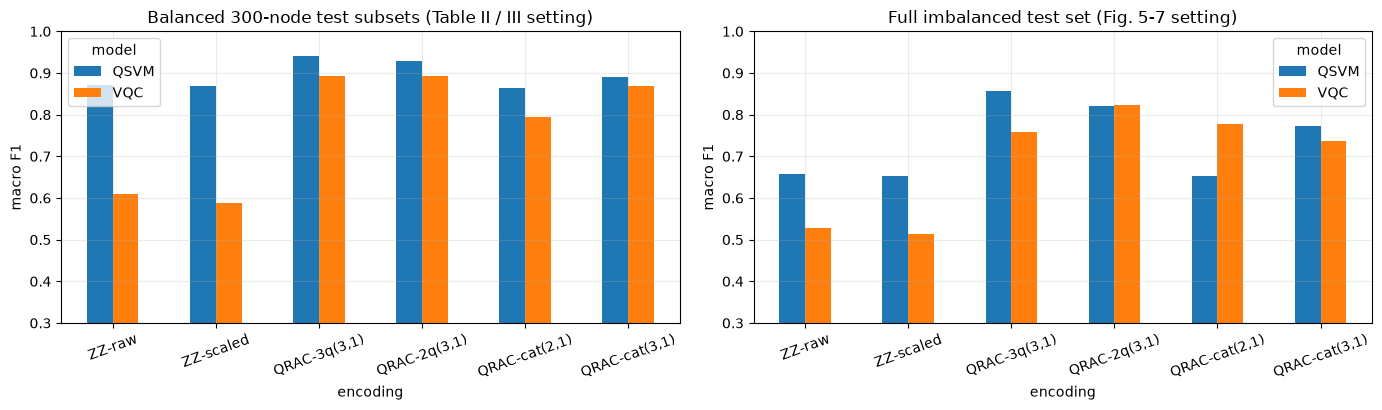

In [30]:
# ---- full results table (all models, mean over seeds) and the headline figure ----
cols = ["full_macro_f1", "full_phish_f1", "full_phish_rec", "full_FN", "full_FP", "bal_macro_f1", "bal_phish_f1", "bal_phish_rec", "t_fit_s", "t_pred_s"]
final = D.groupby(["model", "encoding"], sort=False)[cols].mean().round(3)
display(final)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
order = [n for n in ENCODINGS if n not in ("Z-raw", "AE-raw")]
sub = D[D["model"].isin(["QSVM", "VQC"]) & ~D["encoding"].str.contains("paper median")].groupby(["encoding", "model"], sort=False)[["bal_macro_f1", "full_macro_f1"]].mean().unstack().reindex(order)
sub["bal_macro_f1"].plot.bar(ax=ax[0], rot=20); ax[0].set_title("Balanced 300-node test subsets (Table II / III setting)"); ax[0].set_ylabel("macro F1"); ax[0].set_ylim(0.3, 1)
sub["full_macro_f1"].plot.bar(ax=ax[1], rot=20); ax[1].set_title("Full imbalanced test set (Fig. 5-7 setting)"); ax[1].set_ylabel("macro F1"); ax[1].set_ylim(0.3, 1)
plt.tight_layout(); plt.show()

### What these scores mean at the real prevalence

The test set holds 1 phishing node per 10 normal ones, the balanced subsets 1 per 1, but on the crawled network it is about 1 per 2,500
(paper, Sec. III-A). From a model's true-positive rate and false-positive rate on the test set, the precision it would have at a given
prevalence follows by Bayes' rule; the cell prints it for the main models.

In [31]:
PREV = {"test set (1:10)": 1000 / 11000, "balanced (1:1)": 0.5, "crawl (1:2500)": 1 / 2501}
rows = []
for (m, e), g in D.groupby(["model", "encoding"], sort=False):
    if "paper median" in e or m.startswith("SVC (pre"): continue
    tpr, fpr = g["full_TP"].mean() / (g["full_TP"].mean() + g["full_FN"].mean()), g["full_FP"].mean() / (g["full_FP"].mean() + g["full_TN"].mean())
    rows.append({"model": m, "encoding": e, "TPR (recall)": round(tpr, 3), "FPR": round(fpr, 3),
                 **{f"precision @ {k}": round(tpr * p / (tpr * p + fpr * (1 - p)), 4) for k, p in PREV.items()}})
display(pd.DataFrame(rows))

,model,encoding,TPR (recall),FPR,precision @ test set (1:10),precision @ balanced (1:1),precision @ crawl (1:2500)
0,SVC-rbf,raw-7,0.441,0.032,0.5765,0.9316,0.0054
1,SVC-rbf,bits-7,0.941,0.071,0.5713,0.9302,0.0053
2,SVC-rbf,cat-3,0.979,0.240,0.2902,0.8034,0.0016
3,LGBM,raw-7,0.968,0.085,0.5327,0.9194,0.0045
4,LGBM,bits-7,0.939,0.063,0.5977,0.9369,0.0059
5,LGBM,cat-3,0.891,0.098,0.4749,0.9005,0.0036
6,RandomForest,raw-7,0.969,0.105,0.4804,0.9024,0.0037
7,RandomForest,bits-7,0.941,0.065,0.5907,0.9352,0.0057
8,RandomForest,cat-3,0.877,0.096,0.4777,0.9014,0.0036
9,QSVM,ZZ-raw,0.981,0.238,0.2921,0.8050,0.0016


## Reading the paper critically

**What this notebook reproduces, in one paragraph.** With the authors' own feature files, the QSVM with the 3-qubit (3,1)-QRAC kernel reaches a macro F1 / phishing F1 / phishing recall of 0.94 / 0.94 / 0.94 on balanced 150 + 150 test subsets (paper Table III: 0.93 / 0.94 / 0.96), the annealing QSVM stand-in 0.76 macro F1 (paper 0.78), and the qubit compression of 3.5x holds by construction. The direction of the headline claim (QRAC beats the ZZ feature map for VQC and QSVM) is reproduced, but not its size (+46 % and +8 % against the paper's +13 % and +3 %), because our ZZ baselines are weaker than the paper's (ZZ-QSVM 0.87 against 0.90, ZZ-VQC 0.61 against 0.67). The VQC rows of Table II are not reproduced in either direction: our QRAC-VQC is far better than the paper's (0.89 against 0.72 and 0.76 macro F1) but with a lower phishing recall (0.85-0.91 against 0.93-0.98). In the ablation over 19 ansatzes the binarised QRACs win for 18 of 19 ansatzes (the paper: all except 9, 11 and 16; here the exception is ansatz 1), whereas "both categorised QRACs beat Z, ZZ and AE" holds for only 8 of 19. The claims that QSVM has the fewest false negatives, that the 2-qubit encoding is the best in most ansatzes, and the hardware behaviour of the VQC are **not** reproduced; the real-device numbers cannot be checked. The points below explain why we trust some of these numbers less than their headline suggests.

1. **The binarisation does the work, not the quantum circuit.** A classical RBF-SVM, LightGBM or random forest that sees only the 7 median bits reaches a balanced macro F1 of 0.937-0.939, the same as the best QSVM-QRAC (0.942). A 7-bit input has at most 128 distinct values (39 in the training split, 72 in the 11,000-node test set), so a QRAC kernel is a fixed similarity table over at most 128 inputs. Moreover the 3-qubit and 2-qubit QRAC feature maps contain **no entangling gate**: the states are products of single-qubit states, the kernel factorises into single-qubit overlaps and can be computed in closed form. The transpiled QSVM kernel circuits of Section 9 have two-qubit-gate count 0 and depth 1, which is why they survive 128 shots on a noisy backend. "QSVM-QRAC is robust on NISQ hardware" is true because there is almost nothing for the noise to destroy; it is not evidence of quantum advantage.
2. **The ZZ baseline is weak, which inflates the QRAC gain.** Fed with raw degrees and strengths (values up to 10^4) the ZZ map acts like random phases: the training kernel is almost diagonal (238 of 320 training nodes become support vectors against 80 for QRAC) and the 42-weight VQC trained for 100 COBYLA evaluations barely moves (loss 0.99 to 0.85, macro F1 0.5-0.6). Log-scaling to [0, pi] (`ZZ-scaled`) does not help, so the gap is not just a scaling accident, but a fair comparison would tune the ZZ model too (bandwidth, depth, more iterations; Exercise 3).
3. **Table II looks internally inconsistent.** A phishing recall of 0.98 together with a phishing F1 of 0.53 (VQC-QRAC, 3 qubits) implies a precision of about 0.36, which is only possible on an imbalanced test set (roughly 1 phishing node per 10 normal ones), while the ZZ row (0.67 / 0.63 / 0.55) and Table III look like balanced sets although the caption says "same train and test data". The text mentions both a 300-node and an 11,000-node test set. We therefore give every verdict for both the balanced draws and the full 1:10 test set; neither setting reproduces the VQC rows of Table II.
4. **Balanced test sets hide the deployment problem.** The balanced subsets hold one phishing node per normal node; the crawl has about one per 2,500. With the true-positive and false-positive rates measured on the 1:10 test set, the best model (QSVM, 3-qubit QRAC; recall 0.94, false-positive rate 5.8 %) has a precision of about 0.62 at 1:10 but only about 0.006 at 1:2500 (table above): roughly 150 false alarms per real phishing account. High recall at this precision is a screening tool, not a detector, and a single 300-node subset carries a draw-to-draw standard deviation of 0.01-0.02 macro F1 (column `draw std`), as large as most differences the paper discusses.
5. **"Fewest false negatives" depends on the false positives.** Among the models of Fig. 5, classical LightGBM on the raw features has fewer false negatives (32) than QSVM-QRAC (58), at the price of more false positives (849 against 583). The rows with the very lowest false-negative count (ZZ-QSVM, categorised (2,1)-QRAC) simply flag about a quarter of the normal test nodes as phishing (about 2,400 false positives out of 10,000). A count of false negatives is meaningless without the false positives next to it.
6. **The hardware stand-in does not reproduce the VQC collapse.** The noise model of the fake backends leaves the QRAC-VQC unchanged (0.877 to 0.890 on montreal; the circuit has only 12 two-qubit gates), whereas the paper reports 0.72 to 0.55. Possible causes are the calibration of the day, readout errors that the snapshot underestimates, a different shot budget or test subset, or error sources that a Pauli/relaxation noise model does not capture; the notebook cannot tell. The 7-qubit ZZ-VQC does lose accuracy in the stand-in (0.57 to 0.48, 317 two-qubit gates after routing), the opposite of the paper's "ZZ does not degrade", but it starts from a model that is barely better than chance.
7. **Train and test nodes do not look alike.** The 160 non-phishing training nodes have a mean degree of 2.4, the 10,000 non-phishing test nodes 9.5 (table in the data section), so the two sets were not drawn from the same distribution; every threshold (median, cut-offs) is fitted on the training split and the paper-literal "median over train and test" shifts them (rows `[paper median]`: VQC recall rises to 0.97-0.98 at the price of 1.3-2.6 times as many false positives). Because there is no validation split in the authors' protocol, all choices (ansatz, iterations, thresholds) are made without held-out data, and the single seed of the ablation (the VQC's seed standard deviation is 0.01-0.07) makes per-ansatz differences smaller than about 0.05 meaningless.
8. **Where this notebook deviates.** The 19 benchmark ansatzes are our re-implementation (one layer), the categorisation cut-offs for strength and neighbours and the placement of the third QRAC are our choices, the annealer is replaced by simulated annealing, and the hardware by noise-model simulators. The verdicts on Fig. 6 and Fig. 7 therefore test the paper's statements, not its exact bars.

## Exercises

1. **Median or not.** Re-run with `BIN_MODES = ["train", "paper"]` (the full mode already does) and compare the QRAC rows with their
   `[paper median]` twins. Which test-set information leaks through the "median across the entire training and testing data set" rule, and
   does it change the verdict of C1/C2?
2. **Distinct inputs.** Count the distinct 7-bit patterns in the training and test sets. How many different kernel values can a
   QRAC-QSVM ever produce? What does this say about calling the model a "quantum advantage" candidate, and how would you test it
   against a classical model on the same 128 inputs (hint: the `bits-7` rows in Section 4)?
3. **A fair ZZ baseline.** The ZZ feature map is fed raw degrees and strengths of up to 10^4. Tune a bandwidth (scale all angles by a factor
   chosen on a validation split of the training data) and the number of repetitions, then recompute the +13 % / +3 % claims.
4. **Choosing the ansatz honestly.** The paper picks "the ansatz with the best simulator result". Select the best of the 19 ansatzes on a
   validation split carved out of the training nodes and report the test score of that choice only; compare with the best-on-test number.
5. **Recall first.** Phishing recall matters more than precision here. Add a class weight or a decision threshold to the QSVM
   (`SVC(class_weight=...)`, shifting the decision function on a validation split) and plot recall against the number of false positives for ZZ and QRAC kernels.